# EDA Google Maps theo đúng pipeline Foody

Notebook tham chiếu: `eda._present.ipynb`. Dữ liệu: `../data/raw/ggmap/gmap.json`.

**Câu hỏi:** n-gram 1–3 token nào liên hệ với nhóm điểm thấp và giữ được liên hệ khi chia theo nội dung nhiều lần?

Giữ thứ tự 8 phần Foody; riêng khóa lọc trùng điều chỉnh còn 5 trường theo yêu cầu: **(1)** chất lượng dữ liệu, **(2)** lọc trùng 5 khóa, **(3)** khối lượng văn bản, **(4)** phân phối điểm/độ dài và nội dung lặp, **(5)** đọc mẫu, **(6)** working, **(7)** chia theo text, **(8)** support/lift và ổn định.

## Quy ước ánh xạ trước EDA

| Trường Foody dùng | Trường Maps tương đương | Cách dùng |
|---|---|---|
| `review_id` | `review_id` | Chỉ truy vết/hiển thị, không làm khóa lọc trùng |
| `source_platform` | `source` | Nguồn của review |
| `shop_id` | `restaurant_id` | Định danh địa điểm, không dùng tên quán thay thế |
| `comment_datetime` | `published_at` | Giữ thiếu nếu không có ngày chính xác |
| `rating` | `rating` | Maps 1–5 nhân 2 thành thang 0–10 |
| `comment_text` | `text_raw` | Văn bản gốc, sau đó chuẩn hóa đúng code Foody |

Chỉ 6 trường tương đương trên đi vào `eda`. Các cột `rating_num`, `text_norm`, `n_tokens`, `n_chars`, `is_low` là đặc trưng dẫn xuất giống Foody. Không dùng trường cờ/nhãn/split hoặc thông tin địa lý riêng của Maps để quyết định mẫu, lọc trùng, chọn keyword hay kiểm chứng. Không lấy output của `gg_map.ipynb` làm kết quả.

**Hai hệ quả cần phân biệt:**
- Quy đổi thang điểm là bước ánh xạ đơn vị, không học hay thay đổi cảm xúc. Ngưỡng `0 < rating ≤5` của Foody tương ứng Maps **1–2 sao**. Ba sao chuyển thành 6 điểm, thuộc nhóm còn lại. Đây là tương đương số học, chưa chứng minh tương đương tâm lý người chấm.
- Nếu thiếu ngày đăng, `complete_key=False`. Giữ điều kiện đủ khóa của Foody thì giữ dòng đó, không đổi sang một khóa ngắn hơn và không giả tạo ngày đăng. Khi ấy bước lọc trùng có thể không loại dòng nào, cần ghi nhận giới hạn này.

**Điều chỉnh lần này:** bỏ `device` hoàn toàn khỏi đầu vào và khóa lọc trùng. Năm khóa là `source_platform`, `shop_id`, `comment_datetime`, `rating_num`, `text_norm` (hai khóa cuối là bản chuẩn hóa của rating và comment). `review_id` chỉ dùng truy vết.

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display


## Đọc dữ liệu và đưa về đúng schema Foody

Chỉ lấy các trường tương đương đã liệt kê. Bảng ánh xạ rating giúp kiểm tra rằng ngưỡng ≤5 hoạt động đúng sau đổi thang. `df_raw` lưu bản đầu vào đã ánh xạ trước các bước EDA, không ghi đè JSON gốc.

In [2]:
from pathlib import Path
import json
from IPython.display import Markdown
%matplotlib inline

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'data/raw/ggmap/gmap.json').is_file())
DATA_PATH = ROOT / 'data/raw/ggmap/gmap.json'
SOURCE_TO_FOODY = {
    'review_id': 'review_id',
    'source': 'source_platform',
    'restaurant_id': 'shop_id',
    'published_at': 'comment_datetime',
    'rating': 'rating',
    'text_raw': 'comment_text',
}
with DATA_PATH.open(encoding='utf-8') as handle:
    raw_records = json.load(handle)
if not isinstance(raw_records, list) or not raw_records:
    raise ValueError('Nguồn phải là danh sách review không rỗng.')
absent = set(SOURCE_TO_FOODY) - set().union(*(row.keys() for row in raw_records))
if absent:
    raise ValueError(f'Không tìm thấy trường tương đương: {sorted(absent)}')
eda = pd.DataFrame.from_records(
    [{target: row.get(source) for source, target in SOURCE_TO_FOODY.items()}
     for row in raw_records],
    columns=list(SOURCE_TO_FOODY.values()),
)
del raw_records
# Giữ ID là chuỗi, không suy luận ID thành số.
for col in ['review_id', 'source_platform', 'shop_id']:
    eda[col] = eda[col].astype('string')
original_rating = pd.to_numeric(eda['rating'], errors='coerce')
rating_mapping = original_rating.value_counts(dropna=False).rename_axis('Sao Maps').reset_index(name='Số review')
rating_mapping['Điểm tương đương Foody'] = rating_mapping['Sao Maps'] * 2
rating_mapping['Nhóm thấp sau đổi thang'] = rating_mapping['Điểm tương đương Foody'].between(0, 5)
display(rating_mapping.sort_values('Sao Maps', na_position='last'))
# Giá trị lỗi không chuyển được thành số được giữ nguyên để phase 1 audit.
eda['rating'] = eda['rating'].map(lambda v: v * 2 if isinstance(v, (int, float)) else v)
df_raw = eda.copy(deep=True)
assert list(eda.columns) == list(SOURCE_TO_FOODY.values())
eda.info()

,Sao Maps,Số review,Điểm tương đương Foody,Nhóm thấp sau đổi thang
2,1.0,14784,2.0,True
4,2.0,4777,4.0,True
3,3.0,11096,6.0,False
1,4.0,26042,8.0,False
0,5.0,89856,10.0,False
5,NaN,1010,NaN,False


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 147565 entries, 0 to 147564
Data columns (total 6 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   review_id         147565 non-null  string 
 1   source_platform   147565 non-null  string 
 2   shop_id           147565 non-null  string 
 3   comment_datetime  0 non-null       object 
 4   rating            146555 non-null  float64
 5   comment_text      147565 non-null  object 
dtypes: float64(1), object(2), string(3)
memory usage: 6.8+ MB


## 1. Kiểm tra chất lượng dữ liệu

**Làm gì:** giữ nguyên code Foody để chuẩn hóa NFC, chữ thường, khoảng trắng; audit comment thiếu/rỗng, rating thiếu/không đọc được/ngoài 0–10, rating 0 và text lặp.

**Vì sao:** chỉ review có văn bản và điểm hợp lệ mới tạo được bằng chứng liên hệ text–rating. Đếm text lặp ở đây là khảo sát, chưa xóa theo text.

**Đọc kết quả:** các điều kiện thiếu có thể chồng lấn, không cộng các dòng audit thành tổng bị loại.

In [3]:
required_columns = {"rating", "comment_text"}
missing_columns = required_columns - set(eda.columns)

if missing_columns:
    raise ValueError(f"Thiếu các cột: {sorted(missing_columns)}")

# Giữ toàn bộ cột trong eda để còn khảo sát khóa lọc trùng.
eda["rating_num"] = pd.to_numeric(eda["rating"], errors="coerce")

# Giữ comment gốc; tạo bản chuẩn hóa riêng để thống kê
eda["text_norm"] = (
    eda["comment_text"]
    .astype("string")
    .fillna("")
    .str.normalize("NFC")
    .str.lower()
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

text_missing = eda["comment_text"].isna()
text_empty = eda["text_norm"].eq("")
rating_missing = eda["rating"].isna()
rating_unreadable = (
    eda["rating"].notna() & eda["rating_num"].isna()
)
rating_outside = (
    eda["rating_num"].notna()
    & ~eda["rating_num"].between(0, 10)
)

valid = (
    ~text_empty
    & eda["rating_num"].between(0, 10)
)

audit = pd.Series({
    "Tổng số dòng": len(eda),
    "Comment thiếu": int(text_missing.sum()),
    "Comment rỗng, gồm cả thiếu": int(text_empty.sum()),
    "Rating thiếu": int(rating_missing.sum()),
    "Rating không chuyển được thành số": int(rating_unreadable.sum()),
    "Rating ngoài khoảng 0–10": int(rating_outside.sum()),
    "Dòng có rating = 0": int(eda["rating_num"].eq(0).sum()),
    "Dòng đủ comment và rating hợp lệ": int(valid.sum()),
}, name="Số lượng")

display(audit.to_frame())

# Tập hợp lệ cho audit; chưa lọc comment trùng và vẫn giữ rating 0.
corpus = eda.loc[valid].copy()

if corpus.empty:
    raise ValueError("Không có review đáp ứng điều kiện đầu vào.")

duplicate_text = corpus["text_norm"].duplicated(keep=False)

duplicate_summary = pd.Series({
    "Số nội dung khác nhau": corpus["text_norm"].nunique(),
    "Số dòng thuộc nhóm nội dung lặp": int(duplicate_text.sum()),
    "Số dòng dư nếu chỉ giữ 1 dòng mỗi nội dung":
        int(corpus["text_norm"].duplicated().sum()),
}, name="Số lượng")

display(duplicate_summary.to_frame())

,Số lượng
Tổng số dòng,147565
Comment thiếu,0
"Comment rỗng, gồm cả thiếu",15534
Rating thiếu,1010
Rating không chuyển được thành số,0
Rating ngoài khoảng 0–10,0
Dòng có rating = 0,0
Dòng đủ comment và rating hợp lệ,131021


,Số lượng
Số nội dung khác nhau,124754
Số dòng thuộc nhóm nội dung lặp,7409
Số dòng dư nếu chỉ giữ 1 dòng mỗi nội dung,6267


### Khảo sát rating 0 như Foody

Đọc tối đa 5 review rating 0 rồi đo tỷ trọng trong nhóm ≤5. Nếu không có, bảng mẫu rỗng là kết quả hợp lệ. Không mang nhận định “rating 0 tích cực” của Foody sang Maps khi chưa có dữ liệu.

In [4]:
with pd.option_context("display.max_colwidth", None):
    display(
        eda.loc[eda["rating_num"].eq(0), ["rating", "comment_text"]].head(5)
    )

,rating,comment_text


In [5]:
low_reviews = eda.loc[eda["rating_num"].between(0, 5)]

n_low = len(low_reviews)
n_zero = int(low_reviews["rating_num"].eq(0).sum())
percent_zero = n_zero / n_low * 100 if n_low else 0

print(f"Tổng review điểm thấp (0 ≤ rating ≤ 5): {n_low:,}")
print(f"Số review rating = 0: {n_zero:,}")
print(f"Tỷ lệ rating = 0 trong nhóm điểm thấp: {percent_zero:.4f}%")

Tổng review điểm thấp (0 ≤ rating ≤ 5): 19,561
Số review rating = 0: 0
Tỷ lệ rating = 0 trong nhóm điểm thấp: 0.0000%


### Kết quả phase 1

- Nguồn có **147.565 review**. Comment thiếu dạng null: **0**, nhưng có **15.534 comment rỗng sau chuẩn hóa** (10.53%). Vì vậy nhìn riêng `notna()` sẽ bỏ sót vấn đề văn bản rỗng.
- Có **1.010 review thiếu điểm**. Rating không đọc được: 0, ngoài miền sau đổi thang: 0. Có **131.021 review** đồng thời có text và điểm hợp lệ.
- Rating 0: **0**. Maps hiện tại không cung cấp bằng chứng để lặp lại nhận định rating 0 của Foody. Vẫn giữ đúng bước khảo sát và quy tắc loại rating 0 ở phase 6.

Tập hợp lệ phục vụ phân tích văn bản có thể khác thành phần rating của toàn nguồn. Kết luận keyword phía sau chỉ áp dụng cho tập đã lọc, không cho các review không có văn bản.

## 2. Lọc comment trùng

### 2.1. Kiểm tra thiếu trong đúng 5 trường khóa

`source_platform`, `shop_id`, `comment_datetime`, `rating`, `comment_text`. Giống Foody, chuỗi rỗng và placeholder được tính là thiếu. Việc dùng 6 trường không đồng nghĩa cả 5 đều có đủ ở Maps.

In [6]:
features = [
    "source_platform", "shop_id", "comment_datetime",
    "rating", "comment_text"
]

absent = [col for col in features if col not in eda.columns]
if absent:
    raise ValueError(f"eda thiếu các cột cần thống kê: {absent}")

missing_values = {"", "unknown", "none", "null", "nan", "nat", "<na>", "n/a"}
summary = []

for col in features:
    values = eda[col].astype("string").str.strip().str.lower()
    missing = eda[col].isna() | values.isin(missing_values)
    count = int(missing.sum())
    summary.append({
        "Cột": col,
        "Số review thiếu": count,
        "Tỷ lệ thiếu (%)": round(count / len(eda) * 100, 4) if len(eda) else 0,
    })

print(f"Phạm vi thống kê: toàn bộ {len(eda):,} review, gồm cả rating ≤5 và >5.")
missing_report = pd.DataFrame(summary)
display(missing_report)


Phạm vi thống kê: toàn bộ 147,565 review, gồm cả rating ≤5 và >5.


,Cột,Số review thiếu,Tỷ lệ thiếu (%)
0,source_platform,0,0.0000
1,shop_id,0,0.0000
2,comment_datetime,147565,100.0000
3,rating,1010,0.6844
4,comment_text,15534,10.5269


### 2.2. Giữ đúng điều kiện đầy đủ khóa của Foody

Chỉ loại dòng nếu **đủ cả 5 khóa** và trùng các giá trị chuẩn hóa, giữ dòng đầu tiên. Thiếu ngày đăng thì giữ dòng; không dùng một trường khác để thay thế. `corpus` phải cập nhật từ `eda_clean` và điều kiện hợp lệ phase 1 trước mọi phân tích phía sau.

Bảng theo rating có thể không bao quát review thiếu điểm; dòng “Toàn bộ dataset” là mốc bảo toàn số dòng.

In [7]:
keys = pd.DataFrame(index=eda.index)

for col in ["source_platform", "shop_id", "comment_datetime"]:
    values = eda[col].astype("string").str.normalize("NFC").str.strip()
    keys[col] = values.mask(values.str.lower().isin(missing_values))

# Dùng lại rating và comment đã chuẩn hóa ở phần kiểm tra chất lượng.
keys["rating_num"] = eda["rating_num"]
keys["text_norm"] = eda["text_norm"].replace("", pd.NA)

complete_key = keys.notna().all(axis=1)
duplicate_mask = complete_key & keys.duplicated(keep="first")

eda_clean = eda.loc[~duplicate_mask].copy()
dedup_removed = eda.loc[duplicate_mask].copy()

assert len(eda) == len(eda_clean) + len(dedup_removed)
assert not duplicate_mask.loc[~complete_key].any()

print(f"Tổng review trước lọc: {len(eda):,}")
print(f"Review thiếu khóa, được giữ: {(~complete_key).sum():,}")
print(f"Review trùng bị loại: {len(dedup_removed):,}")
print(f"Tổng review sau lọc: {len(eda_clean):,}")

filter_report = pd.DataFrame([
    {
        "Nhóm": label,
        "Trước lọc": int(mask.sum()),
        "Bị loại": int((mask & duplicate_mask).sum()),
        "Sau lọc": int((mask & ~duplicate_mask).sum()),
    }
    for label, mask in [
        ("Toàn bộ dataset", pd.Series(True, index=eda.index)),
        ("Rating ≤5 (gồm 0)", eda["rating_num"].le(5)),
        ("Rating >5", eda["rating_num"].gt(5)),
    ]
])
display(filter_report)
display(dedup_removed[["review_id"] + features].head(5))

# Dùng lại kết quả kiểm tra hợp lệ trước đó, không kiểm tra lại miền rating.
corpus = eda_clean.loc[valid.loc[eda_clean.index]].copy()


Tổng review trước lọc: 147,565
Review thiếu khóa, được giữ: 147,565
Review trùng bị loại: 0
Tổng review sau lọc: 147,565


,Nhóm,Trước lọc,Bị loại,Sau lọc
0,Toàn bộ dataset,147565,0,147565
1,Rating ≤5 (gồm 0),19561,0,19561
2,Rating >5,126994,0,126994


,review_id,source_platform,shop_id,comment_datetime,rating,comment_text


### Kết quả phase 2

**147.565/147.565 dòng thiếu ít nhất một thành phần khóa**, do ngày đăng chính xác thiếu toàn bộ. Quy tắc 5 khóa loại **0 dòng trùng** và giữ **147.565 dòng** ở bước này.

Điều này có nghĩa **không đủ trường để thực hiện việc loại trùng theo quy tắc hiện tại**, không có nghĩa dữ liệu không chứa bản sao. Tên gọi “sau lọc trùng” chỉ xác định vị trí trong pipeline. Không thay NA bằng một ngày giả và không rút xuống khóa text–quán–điểm vì sẽ đổi phương pháp người dùng yêu cầu.

Sau khi áp điều kiện hợp lệ phase 1 lên `eda_clean`, `corpus` có **131.021 review**. Tất cả thống kê độ dài và phân phối tiếp theo dùng đúng tập này.

## 3. Đo khối lượng văn bản cần xử lý

Giữ tokenizer regex `(?u)w+`: mỗi đoạn liên tiếp gồm ký tự chữ/số/gạch dưới là một token. Với tiếng Việt đây thường là các âm tiết, chưa phải tách từ ghép có ngữ nghĩa. Emoji/dấu câu riêng lẻ không tạo token theo quy tắc này.

`n_chars` đếm ký tự trong `text_norm`, `n_tokens` đếm token regex. Bảng percentile mô tả review điển hình và đuôi dài; chỉ số lượng review chưa cho biết khối lượng xử lý.

In [8]:
import re
TOKEN_PATTERN = r"(?u)\b\w+\b"
token_regex = re.compile(TOKEN_PATTERN)

if corpus.empty:
    raise ValueError("corpus đang rỗng. Cần chạy bước tạo corpus sau lọc trùng.")

corpus["n_tokens"] = corpus["text_norm"].map(
    lambda text: len(token_regex.findall(text))
)
corpus["n_chars"] = corpus["text_norm"].str.len()

print(f"Phạm vi: {len(corpus):,} review hợp lệ sau lọc trùng, ở mọi mức rating.")

length_summary = (
    corpus[["n_tokens", "n_chars"]]
    .describe(percentiles=[0.5, 0.9, 0.95, 0.99])
    .rename(columns={
        "n_tokens": "Số token",
        "n_chars": "Số ký tự",
    })
    .round(1)
)

display(length_summary)

n_no_tokens = int(corpus["n_tokens"].eq(0).sum())

print(f"Comment không có token theo regex: {n_no_tokens:,}")
print(f"Tỷ lệ: {n_no_tokens / len(corpus):.2%}")

Phạm vi: 131,021 review hợp lệ sau lọc trùng, ở mọi mức rating.


,Số token,Số ký tự
count,131021.0,131021.0
mean,39.7,175.3
std,53.0,235.2
min,0.0,1.0
50%,23.0,101.0
90%,90.0,398.0
95%,132.0,580.0
99%,261.0,1159.0
max,960.0,4093.0


Comment không có token theo regex: 82
Tỷ lệ: 0.06%


### Ước lượng lượt 1–3 gram

Với L token, số lượt n-gram dài n là `max(L−n+1, 0)`. “Phục vụ quá chậm” tạo 4 unigram, 3 bigram và 2 trigram, tổng 9 lượt. Đây là lượt phải xét trước đếm binary, không phải số keyword khác nhau hay số cột ma trận.

In [9]:
ngram_volume = pd.DataFrame([
    {
        "Loại": f"{n}-gram",
        "Tổng lượt cụm cần xét": int(
            (corpus["n_tokens"] - n + 1).clip(lower=0).sum()
        ),
    }
    for n in [1, 2, 3]
])

display(ngram_volume)

total_occurrences = int(
    ngram_volume["Tổng lượt cụm cần xét"].sum()
)

print(f"Tổng lượt 1–3 gram cần xét: {total_occurrences:,}")

,Loại,Tổng lượt cụm cần xét
0,1-gram,5199146
1,2-gram,5068207
2,3-gram,4939084


Tổng lượt 1–3 gram cần xét: 15,206,437


### Kết quả phase 3

Trung vị **23 token**, P95 **132 token**, lớn nhất **960 token**. Độ dài có đuôi lớn: không nên lấy review dài nhất làm đại diện cho cách viết thông thường.

Có **82 comment 0 token** dù không rỗng dạng chuỗi. Tổng khối lượng trước đếm binary là **15.206.437 lượt 1–3 gram**. Con số này dùng ước lượng xử lý, không phải số đặc trưng khác nhau. Phần chọn keyword vẫn đếm tối đa một lần mỗi review.

## 4. Phân phối điểm, độ dài và nội dung lặp

### 4.1. Phân phối rating

Vẽ điểm sau quy đổi về 0–10 đúng code Foody và so nhóm ≤5 với >5. Không chỉ đếm keyword trong nhóm thấp vì hai nhóm có thể rất lệch số lượng. Tỷ lệ nền ở biểu đồ là của `corpus`, chưa phải working sau loại rating 0/0 token.

Tổng review: 131,021
Rating ≤5, gồm cả 0: 18,223 (13.91%)
Rating >5: 112,798 (86.09%)


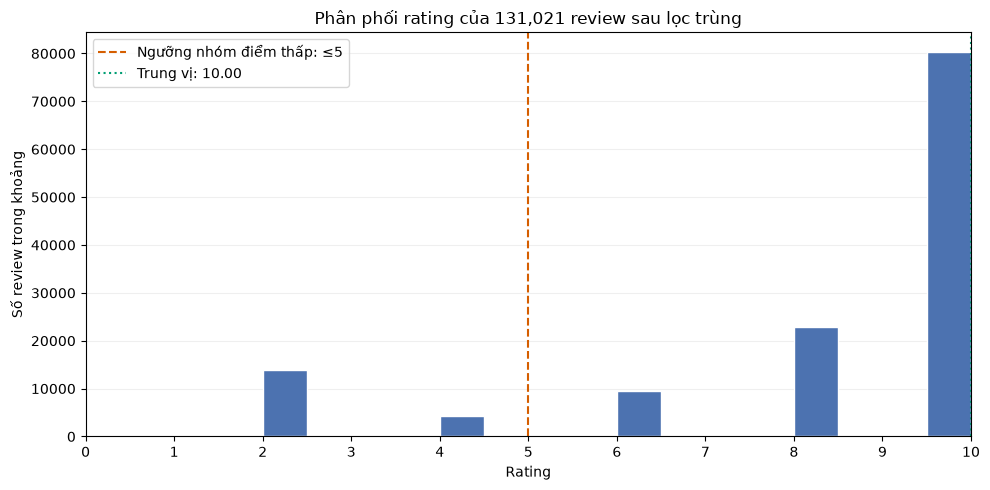

In [10]:
rating = corpus["rating_num"].dropna()

if rating.empty:
    raise ValueError("Không có rating để vẽ.")

n_low = int(rating.le(5).sum())
n_other = int(rating.gt(5).sum())

print(f"Tổng review: {len(rating):,}")
print(f"Rating ≤5, gồm cả 0: {n_low:,} ({n_low / len(rating):.2%})")
print(f"Rating >5: {n_other:,} ({n_other / len(rating):.2%})")

fig, ax = plt.subplots(figsize=(10, 5))

ax.hist(
    rating,
    bins=np.linspace(0, 10, 21),
    color="#4C72B0",
    edgecolor="white",
)

ax.axvline(
    5,
    color="#D55E00",
    linestyle="--",
    label="Ngưỡng nhóm điểm thấp: ≤5",
)

ax.axvline(
    rating.median(),
    color="#009E73",
    linestyle=":",
    label=f"Trung vị: {rating.median():.2f}",
)

ax.set(
    title=f"Phân phối rating của {len(rating):,} review sau lọc trùng",
    xlabel="Rating",
    ylabel="Số review trong khoảng",
    xlim=(0, 10),
    xticks=range(11),
)

ax.legend()
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

### 4.2. Độ dài trên thang thường

Histogram và các đường trung vị/P95 cho thấy mức tập trung và đuôi review dài. Review dài tạo nhiều cơ hội xuất hiện n-gram, nhưng không tự chứng minh rằng độ dài gây điểm thấp.

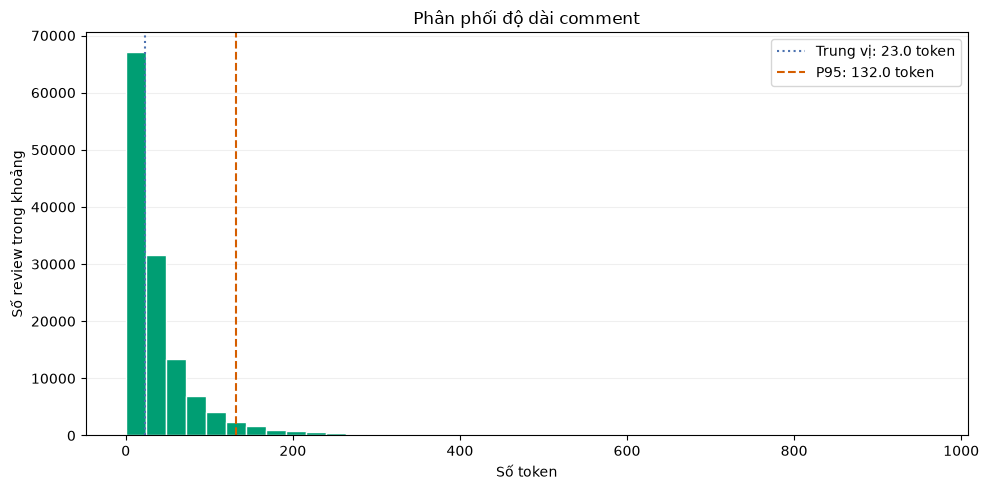

In [11]:
lengths = corpus["n_tokens"].dropna()

fig, ax = plt.subplots(figsize=(10, 5))

ax.hist(
    lengths,
    bins=40,
    color="#009E73",
    edgecolor="white",
)

ax.axvline(
    lengths.median(),
    color="#4C72B0",
    linestyle=":",
    label=f"Trung vị: {lengths.median():.1f} token",
)

ax.axvline(
    lengths.quantile(0.95),
    color="#D55E00",
    linestyle="--",
    label=f"P95: {lengths.quantile(0.95):.1f} token",
)

ax.set(
    title="Phân phối độ dài comment",
    xlabel="Số token",
    ylabel="Số review trong khoảng",
)

ax.legend()
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

### 4.3. Độ dài trên thang log

Dùng lại code Foody để nhìn rõ đồng thời comment ngắn và rất dài. Chỉ review có token được vẽ trên trục log; số review 0 token được báo riêng. Chiều cao là số review trong từng khoảng, các khoảng log không có cùng độ rộng trên thang thường.

Tổng review được đo: 131,021
Review có token: 130,939
Review 0 token, không vẽ trên trục log: 82


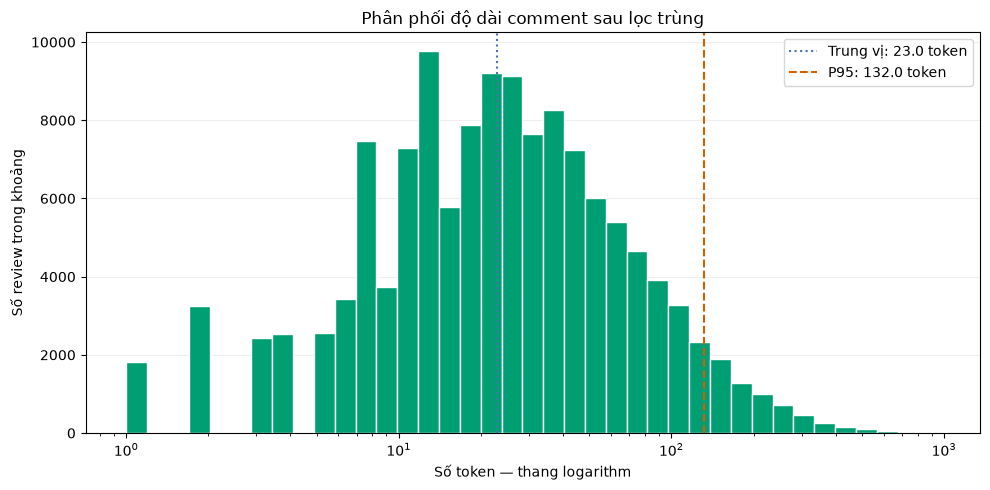

In [12]:
# n_tokens đã được tính ở bước đo khối lượng văn bản.
lengths = corpus["n_tokens"].dropna()
positive_lengths = lengths.loc[lengths.gt(0)]

n_zero = int(lengths.eq(0).sum())

print(f"Tổng review được đo: {len(lengths):,}")
print(f"Review có token: {len(positive_lengths):,}")
print(f"Review 0 token, không vẽ trên trục log: {n_zero:,}")

if positive_lengths.empty:
    raise ValueError("Không có comment có token để vẽ.")

median_length = positive_lengths.median()
p95_length = positive_lengths.quantile(0.95)

# Chia khoảng theo thang logarithm để thể hiện cả phần ngắn và dài.
length_bins = np.geomspace(
    1,
    positive_lengths.max() + 1,
    40,
)

fig, ax = plt.subplots(figsize=(10, 5))

ax.hist(
    positive_lengths,
    bins=length_bins,
    color="#009E73",
    edgecolor="white",
)

ax.set_xscale("log")

ax.axvline(
    median_length,
    color="#4C72B0",
    linestyle=":",
    label=f"Trung vị: {median_length:.1f} token",
)

ax.axvline(
    p95_length,
    color="#D55E00",
    linestyle="--",
    label=f"P95: {p95_length:.1f} token",
)

ax.set(
    title="Phân phối độ dài comment sau lọc trùng",
    xlabel="Số token — thang logarithm",
    ylabel="Số review trong khoảng",
)

ax.legend()
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

### 4.4. Nội dung lặp còn lại

Gom đúng `text_norm` để đếm số review, số quán, số mức rating và số review ≤5. Một câu ngắn có thể do nhiều người viết ở nhiều nơi; không xóa thêm chỉ vì trùng text. Việc thiếu khóa ở phase 2 cũng có thể để lại bản sao, nên số đếm này chưa phải số trải nghiệm độc lập.

In [13]:
# Chọn tất cả dòng thuộc nhóm có text_norm xuất hiện nhiều lần.
# keep=False đánh dấu cả dòng đầu và những dòng xuất hiện sau.
repeated_mask = corpus["text_norm"].duplicated(keep=False)
repeated_reviews = corpus.loc[repeated_mask].copy()

# Tạo cột phụ trên bản sao để đếm nhóm điểm thấp.
repeated_reviews["is_low"] = repeated_reviews["rating_num"].le(5)

duplicate_groups = (
    repeated_reviews
    .groupby("text_norm")
    .agg(
        so_review=("rating_num", "size"),
        so_quan=("shop_id", "nunique"),
        so_muc_rating=("rating_num", "nunique"),
        rating_min=("rating_num", "min"),
        rating_max=("rating_num", "max"),
        so_review_thap=("is_low", "sum"),
    )
    .sort_values("so_review", ascending=False)
    .reset_index()
)

n_repeated = len(repeated_reviews)
pct_repeated = n_repeated / len(corpus) * 100 if len(corpus) else 0

print(f"Tổng review sau lọc: {len(corpus):,}")
print(f"Số nội dung khác nhau: {corpus['text_norm'].nunique():,}")
print(f"Số nhóm nội dung lặp: {len(duplicate_groups):,}")
print(f"Review thuộc các nhóm lặp: {n_repeated:,} ({pct_repeated:.2f}%)")

# Chỉ giới hạn cách hiển thị; không cắt nội dung trong dữ liệu.
with pd.option_context(
    "display.max_colwidth", 180,
    "display.max_columns", None,
):
    display(
        duplicate_groups.head(25).rename(columns={
            "text_norm": "Nội dung chuẩn hóa",
            "so_review": "Số review",
            "so_quan": "Số quán",
            "so_muc_rating": "Số mức rating",
            "rating_min": "Rating thấp nhất",
            "rating_max": "Rating cao nhất",
            "so_review_thap": "Số review ≤5",
        })
    )

Tổng review sau lọc: 131,021
Số nội dung khác nhau: 124,754
Số nhóm nội dung lặp: 1,142
Review thuộc các nhóm lặp: 7,409 (5.65%)


,Nội dung chuẩn hóa,Số review,Số quán,Số mức rating,Rating thấp nhất,Rating cao nhất,Số review ≤5
0,ngon,541,310,5,2.0,10.0,4
1,được rồi,431,282,5,2.0,10.0,15
2,tốt,407,284,5,2.0,10.0,9
3,tuyệt vời,226,186,3,6.0,10.0,0
4,đồ ăn ngon,161,126,4,2.0,10.0,1
5,đẹp,93,72,4,4.0,10.0,1
6,cafe ngon,83,64,4,4.0,10.0,3
7,"đồ ăn ngon, nhân viên nhiệt tình",79,61,1,10.0,10.0,0
8,rất tốt,77,64,3,6.0,10.0,0
9,tạm được,70,66,5,2.0,10.0,6


### Kết quả phase 4

- Histogram rating có phần lớn review ở nhóm điểm cao hơn. Cần so tỷ lệ thấp có điều kiện với baseline riêng, thay vì coi mọi cụm xuất hiện nhiều là dấu hiệu tiêu cực.
- Histogram thường cho thấy đuôi dài, histogram log làm rõ phần review ngắn. Cùng một tập có thể nhìn rất khác khi thay thang trục, không phải dữ liệu đã thay đổi.
- Có **7.409 review thuộc 1.142 nhóm text lặp**, chiếm **5.65% corpus**. Text đứng đầu là **“ngon”**, có 541 review tại 310 địa điểm, trong đó 4 review thấp.

Một câu lặp ở nhiều địa điểm có thể là cách diễn đạt phổ biến. Cùng câu có nhiều mức điểm cho thấy sự xuất hiện n-gram không xác định hoàn toàn rating. Do phase 2 không loại được dòng thiếu khóa, các lượt lặp còn có thể bao gồm bản sao chưa kiểm chứng; không diễn giải mọi lượt là người viết độc lập.

## 5. Đọc mẫu để đối chiếu điểm và văn bản

Giữ đúng các nhóm và seed lấy mẫu của Foody: rating 0, 0 token, ba review dài nhất, mẫu ≤5 và >5. Điểm hiển thị là thang 0–10 đã quy đổi. `review_id` chỉ giúp quay lại bản ghi, không dùng làm khóa hay đặc trưng chọn keyword.

Đọc xem có phủ định, chê/khen từng khía cạnh hoặc điểm không khớp nội dung. Một vài mẫu chỉ xác nhận sự tồn tại của trường hợp, không ước lượng mức phổ biến.

In [14]:
SEED = 42
N_SAMPLE = 5

def show_review_sample(rows, title, n=N_SAMPLE, random_sample=True):
    print(f"\n{title}")
    print(f"Số review trong nhóm: {len(rows):,}")

    if rows.empty:
        print("Không có review thuộc nhóm này.")
        return

    # Nhóm nhỏ hơn n thì hiển thị toàn bộ.
    sample_size = min(n, len(rows))

    if random_sample:
        selected = rows.sample(n=sample_size, random_state=SEED)
    else:
        selected = rows.head(sample_size)

    columns = [
        "review_id",
        "shop_id",
        "rating_num",
        "n_tokens",
        "comment_text",
    ]

    # Hiển thị toàn bộ comment gốc để đọc ngữ cảnh.
    with pd.option_context(
        "display.max_colwidth", None,
        "display.max_columns", None,
    ):
        display(selected[columns])


# 1. Các trường hợp đặc biệt
show_review_sample(
    corpus.loc[corpus["rating_num"].eq(0)],
    "A. Mẫu review rating = 0",
)

show_review_sample(
    corpus.loc[corpus["n_tokens"].eq(0)],
    "B. Mẫu comment không có token theo regex",
)

show_review_sample(
    corpus.nlargest(3, "n_tokens"),
    "C. Ba comment dài nhất",
    n=3,
    random_sample=False,
)


# 2. Mẫu ngẫu nhiên trong từng nhóm rating
show_review_sample(
    corpus.loc[corpus["rating_num"].le(5)],
    "D. Mẫu ngẫu nhiên nhóm rating ≤5 — gồm cả rating 0",
)

show_review_sample(
    corpus.loc[corpus["rating_num"].gt(5)],
    "E. Mẫu ngẫu nhiên nhóm rating >5",
)


A. Mẫu review rating = 0
Số review trong nhóm: 0
Không có review thuộc nhóm này.

B. Mẫu comment không có token theo regex
Số review trong nhóm: 82


,review_id,shop_id,rating_num,n_tokens,comment_text
52287,gmap:5a89df94825ab3c3427b934e14733a90,gmap:147074edb457ea2c33a82508,10.0,0,👌
1416,gmap:0262f9d644c52fc9341df351cca6de09,gmap:5e676dc059fc7d8b3ddf1af3,10.0,0,💯
36828,gmap:3fbd88e88ad6bed1c9283b3849f2f370,gmap:fff6670f74001d5c2e022d8b,10.0,0,💯 …
52980,gmap:5bb64c7ab8405b3616cfd8bd0b3ccdc7,gmap:eaa78c390d849d38710a255b,10.0,0,♥️
30788,gmap:355c7cd0807f1313ab484df171675718,gmap:c706539c8b412efaad37fa73,8.0,0,👌👌👌👌 …



C. Ba comment dài nhất


Số review trong nhóm: 3


,review_id,shop_id,rating_num,n_tokens,comment_text
16676,gmap:1c80e28e8c186674f5f377a20e918e2f,gmap:d13027a90e9ceba7e4983ca7,2.0,960,"Chào mừng bạn đến với bảng nhớ tạm của Gboard, bất kỳ văn bản nào bạn sao chép sẽ được lưu tại đây.Chạm và giữ một đoạn để ghim đoạn đó. Các đoạn đã bỏ ghim sẽ bị xóa sau 1 giờ.Chạm và giữ một đoạn để ghim đoạn đó. Các đoạn đã bỏ ghim sẽ bị xóa sau 1 giờ.Chạm và giữ một đoạn để ghim đoạn đó. Các đoạn đã bỏ ghim sẽ bị xóa sau 1 giờ.Chạm và giữ một đoạn để ghim đoạn đó. Các đoạn đã bỏ ghim sẽ bị xóa sau 1 giờ.Nhấn vào một đoạn để dán vào hộp văn bản.Nhấn vào một đoạn để dán vào hộp văn bản.Sử dụng biểu tượng chỉnh sửa để ghim, thêm hoặc xóa đoạn.Sử dụng biểu tượng chỉnh sửa để ghim, thêm hoặc xóa đoạn.Sử dụng biểu tượng chỉnh sửa để ghim, thêm hoặc xóa đoạn.Sử dụng biểu tượng chỉnh sửa để ghim, thêm hoặc xóa đoạn.Sử dụng biểu tượng chỉnh sửa để ghim, thêm hoặc xóa đoạn.Nhấn vào một đoạn để dán vào hộp văn bản.Nhấn vào một đoạn để dán vào hộp văn bản.Nhấn vào một đoạn để dán vào hộp văn bản.Nhấn vào một đoạn để dán vào hộp văn bản.Nhấn vào một đoạn để dán vào hộp văn bản.Nhấn vào một đoạn để dán vào hộp văn bản.Nhấn vào một đoạn để dán vào hộp văn bản.Nhấn vào một đoạn để dán vào hộp văn bản.Nhấn vào một đoạn để dán vào hộp văn bản.Chào mừng bạn đến với bảng nhớ tạm của Gboard, bất kỳ văn bản nào bạn sao chép sẽ được lưu tại đây.Chạm và giữ một đoạn để ghim đoạn đó. Các đoạn đã bỏ ghim sẽ bị xóa sau 1 giờ.Chạm và giữ một đoạn để ghim đoạn đó. Các đoạn đã bỏ ghim sẽ bị xóa sau 1 giờ.Chạm và giữ một đoạn để ghim đoạn đó. Các đoạn đã bỏ ghim sẽ bị xóa sau 1 giờ.Chạm và giữ một đoạn để ghim đoạn đó. Các đoạn đã bỏ ghim sẽ bị xóa sau 1 giờ.Sử dụng biểu tượng chỉnh sửa để ghim, thêm hoặc xóa đoạn.Sử dụng biểu tượng chỉnh sửa để ghim, thêm hoặc xóa đoạn.Chào mừng bạn đến với bảng nhớ tạm của Gboard, bất kỳ văn bản nào bạn sao chép sẽ được lưu tại đây.Sử dụng biểu tượng chỉnh sửa để ghim, thêm hoặc xóa đoạn.Chào mừng bạn đến với bảng nhớ tạm của Gboard, bất kỳ văn bản nào bạn sao chép sẽ được lưu tại đây.Chào mừng bạn đến với bảng nhớ tạm của Gboard, bất kỳ văn bản nào bạn sao chép sẽ được lưu tại đây.Chào mừng bạn đến với bảng nhớ tạm của Gboard, bất kỳ văn bản nào bạn sao chép sẽ được lưu tại đây.Chào mừng bạn đến với bảng nhớ tạm của Gboard, bất kỳ văn bản nào bạn sao chép sẽ được lưu tại đây.Sử dụng biểu tượng chỉnh sửa để ghim, thêm hoặc xóa đoạn.Sử dụng biểu tượng chỉnh sửa để ghim, thêm hoặc xóa đoạn.Chào mừng bạn đến với bảng nhớ tạm của Gboard, bất kỳ văn bản nào bạn sao chép sẽ được lưu tại đây.Chào mừng bạn đến với bảng nhớ tạm của Gboard, bất kỳ văn bản nào bạn sao chép sẽ được lưu tại đây.Chào mừng bạn đến với bảng nhớ tạm của Gboard, bất kỳ văn bản nào bạn sao chép sẽ được lưu tại đây.Sử dụng biểu tượng chỉnh sửa để ghim, thêm hoặc xóa đoạn.Chạm và giữ một đoạn để ghim đoạn đó. Các đoạn đã bỏ ghim sẽ bị xóa sau 1 giờ.Chạm và giữ một đoạn để ghim đoạn đó. Các đoạn đã bỏ ghim sẽ bị xóa sau 1 giờ.Chạm và giữ một đoạn để ghim đoạn đó. Các đoạn đã bỏ ghim sẽ bị xóa sau 1 giờ.Chạm và giữ một đoạn để ghim đoạn đó. Các đoạn đã bỏ ghim sẽ bị xóa sau 1 giờ.Chạm và giữ một đoạn để ghim đoạn đó. Các đoạn đã bỏ ghim sẽ bị xóa sau 1 giờ.Chạm và giữ một đoạn để ghim đoạn đó. Các đoạn đã bỏ ghim sẽ bị xóa sau 1 giờ.Chào mừng bạn đến với bảng nhớ tạm của Gboard, bất kỳ văn bản nào bạn sao chép sẽ được lưu tại đây.Chào mừng bạn đến với bảng nhớ tạm của Gboard, bất kỳ văn bản nào bạn sao chép sẽ được lưu tại đây.Chào mừng bạn đến với bảng nhớ tạm của Gboard, bất kỳ văn bản nào bạn sao chép sẽ được lưu tại đây.Chào mừng bạn đến với bảng nhớ tạm của Gboard, bất kỳ văn bản nào bạn sao chép sẽ được lưu tại đây.Sử dụng biểu tượng chỉnh sửa để ghim, thêm hoặc xóa đoạn.Sử dụng biểu tượng chỉnh sửa để ghim, thêm hoặc xóa đoạn.Sử dụng biểu tượng chỉnh sửa để ghim, thêm hoặc xóa đoạn.Sử dụng biểu tượng chỉnh sửa để ghim, thêm hoặc xóa đoạn.Sử dụng biểu tượng chỉnh sửa để ghim, thêm hoặc xóa đoạn.Sử dụng biểu tượng chỉnh


D. Mẫu ngẫu nhiên nhóm rating ≤5 — gồm cả rating 0
Số review trong nhóm: 18,223


,review_id,shop_id,rating_num,n_tokens,comment_text
21235,gmap:249cf55121a56f4c75710c38e77bbdf1,gmap:1246a97fc7e26b79f8746f3d,4.0,9,"Quán vỉa bình thường, không có gì đặc sắc"
48517,gmap:53dd15311f492d7b2b6818631febeba4,gmap:cb134a417ea0f46a5929db36,2.0,90,Gọi điện đặt bàn từ lúc 5h chiều đặt bàn 12 người có nói là setup cho chỗ coi đá banh thoáng mát và nhà có nhiều trẻ em. Tới thì nhân viên dắt lên sân thượng rồi dắt xuống vip 1 tất cả mọi người vô phòng ngồi hết thì chủ quán vô kêu chị không phải đặt phòng này chị lên sân thượng dùm em nhà thì 4 đứa nhỏ xíu. Di chuyển 2-3 lần rồi được mời ra. Cách phục vụ tệ nhất chưa từng thấy
62858,gmap:6cef394510f34603ec0da0423f04b1be,gmap:972e4aa1a58abb1947ffb130,4.0,36,"Phục vụ thái độ không thực sự muốn hỗ trợ khách, bưng đồ ra không mời khách. Mình đã uống ở Là Việt mấy năm rồi nhưng chưa cơ sở nào kém dễ thương như vậy"
147110,gmap:ff30bc50e72e6560fd5201ea0913138c,gmap:ef4c0eab9525acde0a54bbd9,2.0,49,"- đi uống nước nhưng mà mất 8k gửi xe\n- nước không ngon, trà đào ko thơm vị như trà đào cho gừng\n- quán có nhiều khách gia đình, xong trẻ con chạy long nhong vừa ồn vừa phiền\nnói chung là không xứng đáng, không bao h quay lại"
34031,gmap:3aee6747ca40fde13005a4b9f6e640e8,gmap:92a8d62f924b9347345942be,2.0,9,Quán gần giờ về làm ăn thiếu chuyên nghiệp



E. Mẫu ngẫu nhiên nhóm rating >5
Số review trong nhóm: 112,798


,review_id,shop_id,rating_num,n_tokens,comment_text
44243,gmap:4c5fdaeb6ba881a520ff1b0b732869e1,gmap:bb4e370bd9016acb19243faf,8.0,5,Ngon hơn những quán khác
18019,gmap:1edebcec51e34f3b9c2d3682ecf66afa,gmap:f5df4b066d709bc2fd2e2a88,10.0,63,"Quán rất lâu đời, chuyên bán bánh bèo nóng, chè đậu xanh, sinh tố.... Bánh bèo ngon, không gian thoáng mát, view nhìn ra biển rất đẹp. Bánh bèo ở đây khá đặc trưng bánh bèo miền trung, topping với bột nhân tôm, bánh mì nướng hạt lựu, nước mắm làm vừa miệng. Sinh tố ở đây tức là trái cây dằm nhé."
108748,gmap:bcd458fc6983df3589c0351d06ae3c6f,gmap:a513eb684711629b56676979,10.0,6,Quán yên tĩnh. Không gian tốt
107299,gmap:ba63e5c00497839f68b004718442b435,gmap:fd5e25e0eaa1cc2ffb35f8ad,8.0,8,Hải anh quá chuyên lẩu hải sản ngon
84566,gmap:9278d28316b27f603070e8928e033a1e,gmap:00fb999b6ad7fc5aba7300d9,10.0,44,Quán bán bánh mì chảo ngon nức lòng giới mộ điệu.\nĐồ ăn được phục vụ nhanh.\nBán từ sáng sớm tới trưa.\nNên đi sáng sớm để thưởng thức món ăn nóng hổi trong tiết trời se lạnh lúc Mặt Trời vừa lên.


### Nhận xét từ mẫu thực tế

- Nhóm rating 0 rỗng. Mẫu zero-token là các biểu tượng như 👌, 💯, ♥️; loại chúng khỏi n-gram là giới hạn biểu diễn regex, không phải kết luận emoji không có cảm xúc.
- Review dài nhất có **960 token**, chứa nội dung hướng dẫn bảng nhớ tạm Gboard và nhiều câu “Chạm và giữ một đoạn để ghim…”. Đây là ví dụ văn bản nhiễu/lặp nội bộ vẫn qua được kiểm tra hợp lệ. Không có bước lọc loại nhiễu này trong code Foody nên notebook giữ lại và ghi rõ giới hạn.
- Mẫu thấp có phàn nàn phục vụ, thiếu chuyên nghiệp, nước không ngon hoặc ý định không quay lại. Mẫu cao hơn có lời khen món ăn, không gian và tốc độ phục vụ. Các ví dụ phù hợp với hướng phân tích liên hệ text–rating, nhưng không xác nhận mọi review được gán điểm đúng cảm xúc.

Không suy tỷ lệ nhiễu hay độ chính xác của rating trên toàn nguồn từ vài dòng này. Bảng giữ nguyên comment để người đọc kiểm tra lại ngữ cảnh.

## 6. Tạo working cho phân tích n-gram

Giữ nguyên quy tắc Foody: loại rating 0 và review 0 token, báo cả phần giao để không cộng trùng số loại. Với Maps, loại rating 0 có thể là phép lọc không tác động nếu nguồn không có điểm 0.

`is_low=True` khi `0 < rating ≤5` trên thang chuẩn hóa, tương ứng 1–2 sao Maps. Nhóm còn lại gồm 3–5 sao. Tất cả phép đếm keyword phải dùng `working` và tỷ lệ nền riêng của tập đang xét.

In [15]:
zero_rating = corpus["rating_num"].eq(0)
zero_tokens = corpus["n_tokens"].eq(0)

remove_mask = zero_rating | zero_tokens

removal_report = pd.DataFrame([
    {"Hạng mục": "Review trước bước lọc này", "Số review": len(corpus)},
    {"Hạng mục": "Có rating = 0", "Số review": int(zero_rating.sum())},
    {"Hạng mục": "Có 0 token", "Số review": int(zero_tokens.sum())},
    {
        "Hạng mục": "Đồng thời rating = 0 và 0 token",
        "Số review": int((zero_rating & zero_tokens).sum()),
    },
    {"Hạng mục": "Tổng review bị loại", "Số review": int(remove_mask.sum())},
    {"Hạng mục": "Review còn lại", "Số review": int((~remove_mask).sum())},
])

display(removal_report)

working = corpus.loc[~remove_mask].copy()

if working.empty:
    raise ValueError("Không còn review để phân tích.")

working["is_low"] = working["rating_num"].le(5)

group_summary = pd.DataFrame({
    "Nhóm": ["0 < rating ≤5", "Rating >5"],
    "Số review": [
        int(working["is_low"].sum()),
        int((~working["is_low"]).sum()),
    ],
})
group_summary["Tỷ lệ (%)"] = (
    group_summary["Số review"] / len(working) * 100
).round(2)

display(group_summary)
print(f"Tỷ lệ điểm thấp trong working: {working['is_low'].mean():.2%}")

,Hạng mục,Số review
0,Review trước bước lọc này,131021
1,Có rating = 0,0
2,Có 0 token,82
3,Đồng thời rating = 0 và 0 token,0
4,Tổng review bị loại,82
5,Review còn lại,130939


,Nhóm,Số review,Tỷ lệ (%)
0,0 < rating ≤5,18221,13.92
1,Rating >5,112718,86.08


Tỷ lệ điểm thấp trong working: 13.92%


### Kết quả phase 6

Từ **131.021 review hợp lệ**, quy tắc rating 0 không loại dòng nào; quy tắc 0 token loại **82 dòng**, còn **130.939 review** cho keyword.

Trong đó **18.221 review thấp**, chiếm **13.9156%**. Đây là nền toàn working, không phải nền cố định dùng cho tất cả split. Nhóm còn lại có **112.718 review**. Ngưỡng thấp giữ đúng ≤5 sau đổi thang, tương đương 1–2 sao Maps.

## 7. Chia discovery/validation 5 lần theo text_norm

Giữ nguyên `GroupShuffleSplit`: 5 lần, `test_size=0.20`, seed 42. Review cùng nội dung chuẩn hóa luôn nằm cùng phía trong một lần chia để tránh thấy lại nguyên câu khi kiểm chứng.

20% là tỷ lệ **nhóm text**, không bắt buộc là 20% dòng và không bảo đảm phân tầng rating. Bảng số dòng và baseline của từng tập dùng để kiểm tra mức lệch. Đây là kiểm chứng EDA, không huấn luyện mô hình. Các split có dùng lại review nên không độc lập.

In [16]:
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit

SEED = 42
N_SPLITS = 5
VALIDATION_SIZE = 0.20

splitter = GroupShuffleSplit(
    n_splits=N_SPLITS,
    test_size=VALIDATION_SIZE,
    random_state=SEED,
)

# Chỉ lưu vị trí dòng để tránh sao chép toàn bộ dữ liệu nhiều lần.
split_indices = []
split_reports = []

for split_id, (disc_pos, val_pos) in enumerate(
    splitter.split(working, groups=working["text_norm"]),
    start=1,
):
    discovery_part = working.iloc[disc_pos]
    validation_part = working.iloc[val_pos]

    overlap = (
        set(discovery_part["text_norm"])
        & set(validation_part["text_norm"])
    )
    assert not overlap

    if any(
        part["is_low"].nunique() < 2
        for part in [discovery_part, validation_part]
    ):
        raise ValueError(
            f"Lần chia {split_id} có tập thiếu một nhóm rating."
        )

    split_indices.append((split_id, disc_pos, val_pos))

    for name, part in [
        ("Discovery", discovery_part),
        ("Validation", validation_part),
    ]:
        split_reports.append({
            "Lần chia": split_id,
            "Tập": name,
            "Số review": len(part),
            "Số text khác nhau": part["text_norm"].nunique(),
            "Review điểm thấp": int(part["is_low"].sum()),
            "Tỷ lệ điểm thấp (%)": round(
                part["is_low"].mean() * 100, 2
            ),
        })

display(pd.DataFrame(split_reports))

,Lần chia,Tập,Số review,Số text khác nhau,Review điểm thấp,Tỷ lệ điểm thấp (%)
0,1,Discovery,104796,99751,14609,13.94
1,1,Validation,26143,24938,3612,13.82
2,2,Discovery,104419,99751,14673,14.05
3,2,Validation,26520,24938,3548,13.38
4,3,Discovery,104330,99751,14540,13.94
5,3,Validation,26609,24938,3681,13.83
6,4,Discovery,105161,99751,14618,13.90
7,4,Validation,25778,24938,3603,13.98
8,5,Discovery,105159,99751,14611,13.89
9,5,Validation,25780,24938,3610,14.00


### Kết quả phase 7

Validation qua 5 lần có **25.778–26.609 review**, baseline **13.38%–14.00%**. Dao động số dòng phù hợp với việc giữ 20% nhóm text chứ không cố định 20% review.

Không có text chuẩn hóa giao giữa hai phía trong từng split theo kiểm tra đã chạy. Tỷ lệ nền không hoàn toàn bằng nhau, nên code tính lift bằng nền của chính tập đó. Tách theo text không bảo đảm tách quán hoặc loại mọi câu gần giống; không suy ra khả năng áp dụng sang quán/thời điểm mới từ kiểm tra này.

## 8. Tìm ứng viên và đánh giá độ ổn định

Sao chép nguyên code và ngưỡng **hiện có trong notebook Foody**, không lấy ngưỡng hay quy tắc từ notebook Maps cũ:

- Từ điển 1–3 gram học trên review thấp của discovery, `min_df=5`.
- Mỗi cụm chỉ đếm một lần mỗi review (`binary=True`). Chọn discovery có lift ≥2.
- Một lần validation đủ bằng chứng khi support validation ≥10. Thiếu mẫu không gán lift bằng 0.
- Ổn định: được chọn ≥4/5 lần, có ≥3 lần đủ mẫu, và ≥80% lần đủ mẫu có lift validation ≥2.

$$\mathrm{Lift}(k)=\frac{P(\mathrm{low}\mid k)}{P(\mathrm{low})}
=\frac{\mathrm{low\_support}(k)/\mathrm{support}(k)}{N_{\mathrm{low}}/N}$$

Lift dùng baseline riêng của discovery/validation tương ứng. Lift =2 nghĩa là tỷ lệ điểm thấp khi có cụm gấp đôi nền. Lift <1 là thấp hơn nền. Các lần thiếu support giữ NaN; min–max không phải khoảng tin cậy. Danh sách ổn định có thể chứa nhiều mảnh câu chồng lấn, không phải mỗi dòng là một chủ đề độc lập.

In [17]:
import numpy as np
from sklearn.feature_extraction.text import CountVectorizer

TOKEN_PATTERN = r"(?u)\b\w+\b"
MIN_LOW_SUPPORT = 5
MIN_LIFT = 2.0
MIN_VALID_SUPPORT = 10
BATCH_SIZE = 5000

MIN_SELECTED_SPLITS = 4
MIN_EVALUABLE_SPLITS = 3
MIN_POSITIVE_RATE = 0.80


def count_support(vectorizer, texts):
    """Đếm số review chứa từng cụm, xử lý theo lô."""
    counts = np.zeros(
        len(vectorizer.get_feature_names_out()),
        dtype=np.int64,
    )

    for start in range(0, len(texts), BATCH_SIZE):
        matrix = vectorizer.transform(
            texts.iloc[start:start + BATCH_SIZE]
        )
        counts += np.asarray(matrix.sum(axis=0)).ravel()
        del matrix

    return counts


run_tables = []
candidate_reports = []

for split_id, disc_pos, val_pos in split_indices:
    disc = working.iloc[disc_pos]
    val = working.iloc[val_pos]

    baseline_disc = float(disc["is_low"].mean())
    baseline_val = float(val["is_low"].mean())

    vectorizer = CountVectorizer(
        token_pattern=TOKEN_PATTERN,
        ngram_range=(1, 3),
        lowercase=False,
        binary=True,
        min_df=MIN_LOW_SUPPORT,
        dtype=np.int32,
    )

    # Tìm ứng viên riêng từ discovery của lần chia hiện tại.
    low_matrix = vectorizer.fit_transform(
        disc.loc[disc["is_low"], "text_norm"]
    )
    low_disc = np.asarray(low_matrix.sum(axis=0)).ravel()
    del low_matrix

    keywords = vectorizer.get_feature_names_out()
    support_disc = count_support(vectorizer, disc["text_norm"])

    lift_disc = (low_disc / support_disc) / baseline_disc

    # Chọn chỉ bằng discovery, chưa nhìn kết quả validation.
    selected = lift_disc >= MIN_LIFT

    candidate_reports.append({
        "Lần chia": split_id,
        "Ứng viên đạt support": len(keywords),
        "Ứng viên có lift discovery ≥2": int(selected.sum()),
    })

    if not selected.any():
        continue

    support_val = count_support(vectorizer, val["text_norm"])
    low_val = count_support(
        vectorizer,
        val.loc[val["is_low"], "text_norm"],
    )

    # Không có review chứa cụm => lift chưa xác định, giữ NaN.
    p_low_val = np.divide(
        low_val,
        support_val,
        out=np.full(len(keywords), np.nan),
        where=support_val > 0,
    )
    lift_val = p_low_val / baseline_val

    run = pd.DataFrame({
        "split": split_id,
        "keyword": keywords[selected],
        "support_discovery": support_disc[selected],
        "low_support_discovery": low_disc[selected],
        "lift_discovery": lift_disc[selected],
        "support_validation": support_val[selected],
        "low_support_validation": low_val[selected],
        "lift_validation": lift_val[selected],
    })

    run["evaluable"] = (
        run["support_validation"] >= MIN_VALID_SUPPORT
    )
    run["positive_validation"] = run["lift_validation"] >= MIN_LIFT

    run_tables.append(run)

    print(
        f"Lần {split_id}: chọn {len(run):,} cụm; "
        f"{run['evaluable'].sum():,} cụm đủ mẫu kiểm chứng."
    )

display(pd.DataFrame(candidate_reports))

if not run_tables:
    raise ValueError("Không có ứng viên đạt điều kiện discovery.")

keyword_runs = pd.concat(run_tables, ignore_index=True)

# Số lần keyword được chọn trên discovery.
selection_summary = keyword_runs.groupby("keyword").agg(
    n_selected=("split", "nunique"),
    median_discovery_lift=("lift_discovery", "median"),
)

# Chỉ tổng hợp lift validation ở những lần có đủ mẫu.
validation_summary = (
    keyword_runs.loc[keyword_runs["evaluable"]]
    .groupby("keyword")
    .agg(
        n_evaluable=("split", "nunique"),
        positive_rate=("positive_validation", "mean"),
        median_validation_lift=("lift_validation", "median"),
        min_validation_lift=("lift_validation", "min"),
        max_validation_lift=("lift_validation", "max"),
    )
)

keyword_stability = (
    selection_summary
    .join(validation_summary, how="left")
    .reset_index()
)

keyword_stability["n_evaluable"] = (
    keyword_stability["n_evaluable"].fillna(0).astype(int)
)

keyword_stability["stable"] = (
    keyword_stability["n_selected"].ge(MIN_SELECTED_SPLITS)
    & keyword_stability["n_evaluable"].ge(MIN_EVALUABLE_SPLITS)
    & keyword_stability["positive_rate"].ge(MIN_POSITIVE_RATE)
)

keyword_stability["assessment"] = np.select(
    [
        keyword_stability["n_evaluable"].lt(MIN_EVALUABLE_SPLITS),
        keyword_stability["stable"],
    ],
    [
        "Chưa đủ lần kiểm chứng",
        "Ổn định theo ngưỡng",
    ],
    default="Chưa ổn định theo ngưỡng",
)

keyword_stability = keyword_stability.sort_values(
    ["stable", "n_selected", "n_evaluable", "positive_rate"],
    ascending=False,
).reset_index(drop=True)

print("\nSố keyword theo kết quả đánh giá:")
display(
    keyword_stability["assessment"]
    .value_counts()
    .rename_axis("Đánh giá")
    .to_frame("Số keyword")
)

# Tạo bảng hiển thị; không làm tròn dữ liệu dùng để phân tích.
preview = keyword_stability.head(50).copy()
preview["positive_rate"] = preview["positive_rate"] * 100

display(
    preview.rename(columns={
        "keyword": "Cụm",
        "n_selected": "Số lần được chọn /5",
        "n_evaluable": "Số lần đủ mẫu validation",
        "positive_rate": "% lần đủ mẫu có lift ≥2",
        "median_discovery_lift": "Lift discovery trung vị",
        "median_validation_lift": "Lift validation trung vị",
        "min_validation_lift": "Lift validation nhỏ nhất",
        "max_validation_lift": "Lift validation lớn nhất",
        "stable": "Đạt tiêu chí ổn định",
        "assessment": "Đánh giá",
    }).round(3)
)

Lần 1: chọn 30,898 cụm; 6,253 cụm đủ mẫu kiểm chứng.


Lần 2: chọn 31,064 cụm; 6,202 cụm đủ mẫu kiểm chứng.


Lần 3: chọn 30,634 cụm; 6,323 cụm đủ mẫu kiểm chứng.


Lần 4: chọn 31,007 cụm; 6,280 cụm đủ mẫu kiểm chứng.


Lần 5: chọn 30,388 cụm; 6,256 cụm đủ mẫu kiểm chứng.


,Lần chia,Ứng viên đạt support,Ứng viên có lift discovery ≥2
0,1,44723,30898
1,2,45063,31064
2,3,44434,30634
3,4,44775,31007
4,5,44267,30388



Số keyword theo kết quả đánh giá:


,Số keyword
Đánh giá,
Chưa đủ lần kiểm chứng,33633
Ổn định theo ngưỡng,4592
Chưa ổn định theo ngưỡng,1315


,Cụm,Số lần được chọn /5,Lift discovery trung vị,Số lần đủ mẫu validation,% lần đủ mẫu có lift ≥2,Lift validation trung vị,Lift validation nhỏ nhất,Lift validation lớn nhất,Đạt tiêu chí ổn định,Đánh giá
0,0,5,4.106,5,100.0,4.683,3.669,5.020,True,Ổn định theo ngưỡng
1,1,5,2.259,5,100.0,2.332,2.231,2.383,True,Ổn định theo ngưỡng
2,1 bàn,5,3.534,5,100.0,3.366,2.770,4.017,True,Ổn định theo ngưỡng
3,1 bát,5,2.547,5,100.0,2.935,2.431,3.163,True,Ổn định theo ngưỡng
4,1 bạn,5,4.464,5,100.0,4.396,4.204,4.683,True,Ổn định theo ngưỡng
5,1 bạn nhân,5,5.078,5,100.0,5.120,4.519,5.713,True,Ổn định theo ngưỡng
6,1 con,5,2.873,5,100.0,3.076,2.657,3.258,True,Ổn định theo ngưỡng
7,1 cái,5,3.300,5,100.0,3.489,3.172,3.651,True,Ổn định theo ngưỡng
8,1 câu,5,6.412,5,100.0,6.196,5.997,6.852,True,Ổn định theo ngưỡng
9,1 cốc,5,3.774,5,100.0,3.860,3.437,4.428,True,Ổn định theo ngưỡng


### Kết quả phase 8

| Đánh giá | Số n-gram |
|---|---:|
| Ổn định theo ngưỡng | 4.592 |
| Chưa đủ lần kiểm chứng | 33.633 |
| Chưa ổn định theo ngưỡng | 1.315 |

“Ổn định” chỉ có nghĩa vượt các điều kiện 4/5 lần chọn, ≥3 lần đủ mẫu và ≥80% lần đủ mẫu đạt lift ≥2. Một n-gram thiếu mẫu chưa bị kết luận không có liên hệ. Nhiều n-gram là các mảnh chồng lấn của cùng một câu nên **4.592 dòng không tương đương từng ấy chủ đề**.

Bảng 50 dòng gốc giữ nguyên cách sắp xếp của code Foody, không phải bảng top theo độ phủ. Phần 8.1 bên dưới chỉ sắp cách hiển thị sau khi nhãn ổn định đã chốt.

### 8.1. Đọc ứng viên sau khi đã chốt độ ổn định

Giữ nguyên tập ứng viên/nhãn ổn định ở trên. Chỉ bổ sung cách đọc trên toàn `working`: support, tỷ lệ thấp khi chứa cụm, lift mô tả và độ phủ nhóm thấp. Xếp theo độ phủ để xem cụm nào xuất hiện trong nhiều review thấp hơn, không chọn lại bằng validation hay ngưỡng khác.

- `coverage_low_pct = low_support_all / tổng review thấp ×100`.
- `coverage_all_pct = support_all / tổng working ×100`.
- `lift_all` là mô tả toàn working, khác `median_validation_lift` dùng kiểm chứng.

Các độ phủ chồng lấn vì một review có nhiều cụm, không cộng thành độ phủ toàn danh sách.

,keyword,support_all,low_support_all,coverage_low_pct,coverage_all_pct,p_low_pct,baseline_pct,lift_all,n_selected,n_evaluable,positive_rate,median_validation_lift
0,thì,24815,7831,42.978,18.952,31.558,13.916,2.268,5,5,1.0,2.289
1,khách,17470,6219,34.131,13.342,35.598,13.916,2.558,5,5,1.0,2.574
2,mà,17062,5900,32.380,13.030,34.580,13.916,2.485,5,5,1.0,2.513
3,1,14930,4725,25.932,11.402,31.648,13.916,2.274,5,5,1.0,2.332
4,tệ,5279,4602,25.257,4.032,87.176,13.916,6.265,5,5,1.0,6.329
5,ra,11959,4539,24.911,9.133,37.955,13.916,2.727,5,5,1.0,2.741
6,như,13334,4237,23.253,10.183,31.776,13.916,2.283,5,5,1.0,2.255
7,thái,7135,4013,22.024,5.449,56.244,13.916,4.042,5,5,1.0,4.069
8,độ,6777,3935,21.596,5.176,58.064,13.916,4.173,5,5,1.0,4.196
9,ko,10990,3802,20.866,8.393,34.595,13.916,2.486,5,5,1.0,2.505


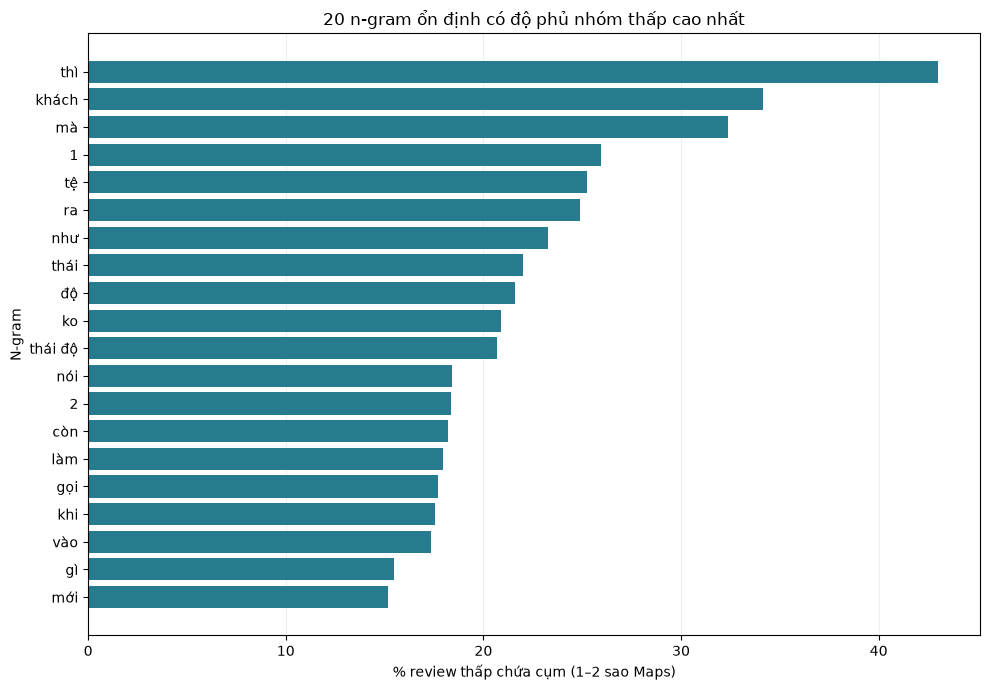

In [18]:
stable_results = keyword_stability.loc[keyword_stability['stable']].copy()
baseline_all = float(working['is_low'].mean())
if not stable_results.empty:
    stable_vectorizer = CountVectorizer(
        vocabulary={term: i for i, term in enumerate(stable_results['keyword'])},
        token_pattern=TOKEN_PATTERN, ngram_range=(1, 3),
        lowercase=False, binary=True, dtype=np.int32,
    )
    stable_vectorizer.fit(working['text_norm'].iloc[:1])
    stable_results['support_all'] = count_support(stable_vectorizer, working['text_norm'])
    stable_results['low_support_all'] = count_support(
        stable_vectorizer, working.loc[working['is_low'], 'text_norm'])
    stable_results['p_low_pct'] = 100 * stable_results['low_support_all'] / stable_results['support_all']
    stable_results['baseline_pct'] = 100 * baseline_all
    stable_results['lift_all'] = stable_results['p_low_pct'] / (100 * baseline_all)
    stable_results['coverage_low_pct'] = 100 * stable_results['low_support_all'] / working['is_low'].sum()
    stable_results['coverage_all_pct'] = 100 * stable_results['support_all'] / len(working)
    stable_results = stable_results.sort_values(
        ['coverage_low_pct', 'support_all', 'keyword'], ascending=[False, False, True]).reset_index(drop=True)
    columns = ['keyword', 'support_all', 'low_support_all', 'coverage_low_pct',
               'coverage_all_pct', 'p_low_pct', 'baseline_pct', 'lift_all',
               'n_selected', 'n_evaluable', 'positive_rate', 'median_validation_lift']
    display(stable_results[columns].head(30).round(3))
    chart = stable_results.head(20).iloc[::-1]
    fig, ax = plt.subplots(figsize=(10, 7))
    ax.barh(chart['keyword'], chart['coverage_low_pct'], color='#267b8e')
    ax.set(title='20 n-gram ổn định có độ phủ nhóm thấp cao nhất',
           xlabel='% review thấp chứa cụm (1–2 sao Maps)', ylabel='N-gram')
    ax.grid(axis='x', alpha=.2)
    ax.set_axisbelow(True)
    plt.tight_layout()
    plt.show()
else:
    print('Không có n-gram đạt đủ tiêu chí ổn định. Không tự nới ngưỡng.')

### 8.2. Ngữ cảnh của các cụm có độ phủ cao

Lấy tự động 3 cụm dài 2–3 token có độ phủ nhóm thấp cao nhất từ danh sách ổn định, không chỉ định trước từ nào “đẹp”. Tìm theo đúng tokenizer của vectorizer rồi lấy tối đa 2 review thấp và 2 review còn lại mỗi cụm, seed 42. Mẫu có thể chứa nội dung ngoài nhà hàng vì không dùng trường loại địa điểm để lọc.

Đây là bước đọc kết quả, không đổi working hay nhãn stable. Giữ nguyên văn bản và rating trong bảng để kiểm tra phủ định, mảnh câu và lời khen/chê hỗn hợp.

In [19]:
context_samples = {}
context_terms = stable_results.loc[stable_results['keyword'].str.split().str.len().ge(2), 'keyword'].head(3).tolist()
if context_terms:
    context_vectorizer = CountVectorizer(
        vocabulary={term: i for i, term in enumerate(context_terms)},
        token_pattern=TOKEN_PATTERN, ngram_range=(1, 3), lowercase=False, binary=True)
    context_matrix = context_vectorizer.fit_transform(working['text_norm'])
    for j, term in enumerate(context_terms):
        has_term = np.asarray(context_matrix[:, j].toarray()).ravel().astype(bool)
        print(f'\nCụm: {term}')
        for low, label in [(True, 'Nhóm thấp'), (False, 'Nhóm còn lại')]:
            part = working.loc[has_term & working['is_low'].eq(low)]
            print(f'{label}: {len(part):,} review chứa cụm')
            sample = part.sample(min(2, len(part)), random_state=SEED)
            selected = sample[['review_id', 'shop_id', 'rating_num', 'n_tokens', 'comment_text']]
            context_samples[f'{term} / {label}'] = selected.to_dict(orient='records')
            with pd.option_context('display.max_colwidth', None):
                display(selected)


Cụm: thái độ
Nhóm thấp: 3,773 review chứa cụm


,review_id,shop_id,rating_num,n_tokens,comment_text
3400,gmap:05c0224992179c99e4580cf4af709564,gmap:dce24783630bdfebc7b5a280,2.0,73,"nước đắt. quán tầng 3 cũng tạm ổn, chỗ ngồi bệt, có máy chiếu nhé, có hỗ trợ loa mic. nma nhân viên có vẻ khó chịu, ko vui vẻ phục vụ khác cho lắm :)) mình đi đông hơn hơn 25 người, có ng đến trc ng đến sau quên k order ghi ra giấy mà order mồm thôi xong cái a nhân viên nam ca tối cực kì thái độ lồi lõm"
147486,gmap:ffd96f7e09f3bd374c5cba572b38c16f,gmap:6e1bc01bb1c4865e7fd840c5,2.0,83,"Quán quá lù đù, quản lý quá kém tới trước order trước vẫn phải đợi món sau, gọi có 6 con hàu phô mai đợi hơn 1 tiếng đồng hồ vẫn chx có, r quán báo hàu đang giao tới trong khi ban đầu bảo là có hàu???? Đồ ăn qa đắt nhx k đc thái độ phục vụ đúng v giá tiền, quán nên xem lại thái độ phục vụ và quản lý số lượng thực phẩm trong quán, quá vô dụng."


Nhóm còn lại: 1,427 review chứa cụm


,review_id,shop_id,rating_num,n_tokens,comment_text
14050,gmap:17e5be32840d5ae0706e5b3962873049,gmap:a13055f3bbebfe4ce6e62cf0,8.0,10,"Nvien thái độ tốt, không gian riêng tư, thoải mái."
121505,gmap:d2feecadcad02cd79a78d735d4c07515,gmap:1777be7666549d5628e5c704,10.0,286,"Hôm nay mình có hẹn đi lấy visa nên đi cùng bạn và về hơi trễ. Lúc tới vào quán thì thấy cô cười chào hỏi niềm nỡ lắm. 2 bọn mình có gọi xuất nem nướng và bánh xèo tôm thêm 1 cốc nước. Đợi tầm 5-7p bọn mình đã có đồ ăn. Đánh giá về đồ ăn thì mình thấy nem nướng ăn rất ngon, nước chấm hợp khẩu vị và có thể nói ngon nhất mình từng ăn, phần nem nướng thì mình khá ấn tượng bởi lớp sốt cam cam( kh rõ là gì) ăn rất hợp với đồ ăn kèm. Phần bánh xèo tôm thì vỏ giòn rụm, ngon. Siêu siêu rì com men mn ăn 2 món này (rau cũng tươi nữa nhen). Về phần nước thì bọn mình gọi 1 trà chanh lá dứa, theo cá nhân mình là 1 đứa kh thic ăn ngọt ( rất ghét đồ ngọt) thì nó ngọt, mình quấy nh lần và để lâu cho đá tan bớt thì vẫn ngọt nhưng với bạn mình thì cx khá ok( nếu tới ai kh thic đồ ngọt thì gọi nước khác nhen) Có thể giải ngấy. Cô còn thân thiện, bọn mình gọi 1 ly nhưng cô bê ra 2 ly cuối giờ nọn mình có bảo trả cả 2 ly thì cô nhất quyết chỉ thanh toán 1 ly và bảo tặng ly kia. Cô còn vui vẻ niềm nỡ khi khách về... Lúc mình đi không có nhân viên nên kh biết thái độ nv như nào. Tuy chỉ có mình cô nhưng đồ lên khá nhanh và chuẩn chỉnh. Lần sau về VN mình chắc chắn sẽ lại tới tìm quán🫶🫶🫶."



Cụm: không có
Nhóm thấp: 1,825 review chứa cụm


,review_id,shop_id,rating_num,n_tokens,comment_text
45778,gmap:4efc65c013c2fc74d028e24a902aceb9,gmap:9ba2081f2c9f5382314dd0f6,2.0,83,"làm dịch vụ nhưng thái độ không thể chấp nhận được!.\nNên ĐỔI CHỦ thì tốt hơn - mình không có chuyên môn làm dịch vụ thì nên thuê người khác.\nKhách nóng xin quạt mà xúc phạm người ta, thấy mà tức.\n.....\nXin tt liên hệ để làm gì, phải thay đổi từ chính dịch vụ của quán, ở đây không phải nghe kể mà là chứng kiến, là trải nghiệm tồi, không phải thông tin sai sự thật, không cần đính chính."
141220,gmap:f4f415b669695a2d91c939ce8dd8b8e8,gmap:20e0081bbe00a69031e95a3b,2.0,16,Bạc xỉu nhạt như nước lọc. Giá thì đắt không có lần 2 ngồi ở đây


... (2 outputs left out)


Cụm: khách hàng
Nhóm thấp: 1,307 review chứa cụm


,review_id,shop_id,rating_num,n_tokens,comment_text
131524,gmap:e42cf7ceb58e7007e3c3c9d61137874d,gmap:c2a48f33e39a02f2fc17f841,2.0,63,"1. Quán rất nhỏ, không có chỗ ngồi. Chủ quán keo kiệt không chịu chi tiền thuê sân cho khách ngồi.\n2. Đồ ăn ra rất lâu, 30 phút ra được 1 món.\n3. Giá cao, bán mắc.\n4. Phục vụ thiếu chuyên nghiệp, không lắng nghe yêu cầu của khách.\n5. Chủ quán thờ ơ, không sâu sát trải nghiệm khách hàng."
118624,gmap:ce0da2467d35ea18c480790047f1b466,gmap:2ad2dd6c24780e12717ccc8b,4.0,175,"Thái độ nhân viên Vân (Sa) thiếu tích cực,không thân thiện với khách hàng, giải quyết tình huống kém. Mình gọi cà phê sữa 49k đưa 100k bạn bảo không có tiền thối kêu mình chuyển khoản,nhưng mình vừa rút hết tiền trong thẻ ra nên bảo bạn là đây là tờ mệnh giá nhỏ nhất mình có, trong thẻ ko đủ, nếu chưa có tiền thối thì có thể giữ lại đi lát thối mình sau cũng được. Sau đó bạn đưa cho mình cái thẻ chờ và không nói gì cả. Mình đứng tầm 10 giây thì bạn nói ""Của a xong rồi đó"", không hoá đơn không note gì lại là nợ mình 51k cũng không một câu cảm ơn. Mình không cần biết các bạn đang đông nên có hơi mệt hay gì nhưng cách cư xử và thái độ của bạn là thứ mình không chấp nhận được khi bỏ tiền ra sử đụng dịch vụ của HighLand. Mong các bạn cải thiện hơn khâu training nhân sự."


Nhóm còn lại: 1,483 review chứa cụm


,review_id,shop_id,rating_num,n_tokens,comment_text
14282,gmap:185123bd9174294597d07b32545f4aaa,gmap:95ad6c911e44a4d980dfd128,10.0,134,Nói chung là rất tốt đối với số lượng khách và số lượng thực phẩm khi yêu cầu.Nhân viên phục vụ cho việc ăn uống của khách rất tốt và cách thức nói chuyện cũng không gây phiền hà cho khách.Nếu có dịp sẽ mời bạn bè đến nhà hàng để thưởng thức thêm những món ăn khác.Nói chung từ anh bảo vệ hay nhân viên phục vụ đều dễ mến và ân cần phục vụ cho khách hàng.Tôi thấy cháu Hoàng Yến tuy là một thu ngân nhưng cũng tham gia chào đón và ân cần phục vụ cho khách.Mong rằng tất cả nhân viên nhà hàng luôn mạnh khỏe và phục vụ cho khách hàng được thoải mái tinh thần khi vào nhà hàng Hoàng Yến.thank.!!!
44965,gmap:4d90ce329b8ff8e70d2524eb2e29d9a3,gmap:1ab6d7d75bd01465cd782759,10.0,256,"Mình Recommend mọi người nhà hàng chay này nha, có thể dùng bữa cùng gia đình, bạn bè hay đối tác đều hợp và mình biết đến nhà hàng qua GG ấn tượng đầu tiên trước khi vào là anh Bảo Vệ rất nhiệt tình và niềm nở, ấn tượng thứ hai là không gian mộc mạc và gần gũi ai thích hoà mình vào thiên nhiên thì có thể ngồi phía ngoài sân vườn, còn thích ấm cúng thì mọi người ngồi phía trong, có tiếng thác và tiếng chim tạo cảm giác thoải mái dễ chịu, chill chill với tiếng nhạc giúp mình được thư giãn.\nVề dịch vụ thì mình thấy nhân viên nhẹ nhàng lịch sự,tận tâm với khách hàng\nVề món ăn thì được nêm nếm vừa miệng, hợp khẩu vị ạ, menu đa dạng, nhiều rau củ tươi và các loại nấm, còn có nhiều món mới nữa đến không nổi mình chọn nhiều quá vì món nào cũng muốn thử, hên bạn nhân viên tư vấn món vừa đủ no cho bàn mình luôn rất ưng bụng, mình thích nhất món nấm mối sốt trứng muối và miếng xào măng, hoặc mọi người có thể thử những món ăn chơi như đậu hủ non sốt nấm hoặc sake lắc phô mai, mặc dù ngay trung tâm thành phố nhưng giá thành lại không quá cao mình thấy khá là hợp lí với mình đi 3 người ăn cũng được khá nhiều món, sẽ tiếp tục ủng hộ ạ."


## Kết luận từ lần chạy này

**Câu trả lời:** có **4.592 n-gram** liên hệ với nhóm thấp và đạt tiêu chí ổn định trên cách chia theo text của Foody. Các cụm có độ phủ cao gồm “thì”, “khách”, “mà”, “1”, “tệ”. Bảng dưới trích trực tiếp từ kết quả, xếp theo độ phủ nhóm thấp:

| Cụm | Review thấp / review chứa cụm | Độ phủ nhóm thấp | Lift validation trung vị |
|---|---:|---:|---:|
| thì | 7.831/24.815 | 42.98% | 2.289 |
| khách | 6.219/17.470 | 34.13% | 2.574 |
| mà | 5.900/17.062 | 32.38% | 2.513 |
| 1 | 4.725/14.930 | 25.93% | 2.332 |
| tệ | 4.602/5.279 | 25.26% | 6.329 |
| ra | 4.539/11.959 | 24.91% | 2.741 |
| như | 4.237/13.334 | 23.25% | 2.255 |
| thái | 4.013/7.135 | 22.02% | 4.069 |
| độ | 3.935/6.777 | 21.60% | 4.196 |
| ko | 3.802/10.990 | 20.87% | 2.505 |

### Liên hệ thống kê chưa đồng nghĩa “từ tiêu cực”

“Thì”, “mà”, “khách” hoặc số “1” có thể đạt ngưỡng dù bản thân không biểu đạt bất mãn. “Thì” phủ khoảng **42,98% review thấp**, nhưng điều này chỉ chứng minh cách diễn đạt đó phổ biến hơn mức nền trong nhóm thấp. Nó có thể đi cùng cách kể trải nghiệm hoặc độ dài văn bản; notebook chưa kiểm tra riêng để xác định nguyên nhân. Không gọi toàn bộ danh sách là “fatal keywords” chỉ vì đạt support/lift.

“Tệ” có **4.602/5.279 review chứa cụm thuộc nhóm thấp**, còn “thái độ” có **3.773/5.200**. Đây là các tín hiệu có thể diễn giải rõ hơn, nhưng vẫn cần đọc câu. Mẫu cao hơn chứa đúng câu **“Nvien thái độ tốt, không gian riêng tư, thoải mái.”**, cho thấy “thái độ” không phải quy tắc tiêu cực độc lập. Với “không có”, mẫu vừa có chê món vừa có tổng thể 4 sao; “khách hàng” cũng xuất hiện trong lời khen phục vụ. Đó là bằng chứng về sự cần thiết của ngữ cảnh, không phải lỗi tính lift.

**Cách đọc:** độ phủ cao cho biết liên hệ liên quan nhiều review thấp trong mẫu, còn lift lớn cho biết tỷ lệ thấp khi có cụm vượt nền. Một cụm có thể phủ nhiều review nhưng không có lift cao nhất. Không cộng độ phủ các dòng vì có review chứa nhiều cụm. Lift toàn tập và lift validation trung vị là hai phép tổng hợp khác nhau.

**Khác biệt phương pháp so với notebook Maps cũ:** phân tích này chỉ lấy các trường tương đương Foody, dùng văn bản gốc qua đúng bộ chuẩn hóa, không dùng cờ/nhãn/split riêng của Maps. Sau khi bỏ device, thiếu ngày đăng vẫn khiến bước lọc trùng không loại dòng nào. Vì đầu vào văn bản và cách giữ dòng khác, không yêu cầu số review hoặc keyword trùng notebook Maps cũ.

**Giới hạn còn lại:** mẫu chỉ gồm review có điểm và token; chưa loại được bản sao thiếu khóa; vẫn có nhiễu dán nội dung; regex n-gram không nắm đủ phủ định và đánh giá nhiều khía cạnh; rating là điểm người dùng chứ chưa phải ground truth cảm xúc. Việc chia theo text vẫn có thể dùng cùng quán ở hai phía và không loại mọi biến thể gần giống.

Nếu cải tiến tiếp, cần thu thập ngày đăng đáng tin cậy để áp khóa hiện tại, hoặc định nghĩa riêng một chính sách lọc trùng rồi báo đó là thay đổi phương pháp. Có thể audit mẫu nhiễu và gán nhãn ngữ cảnh trước khi đánh giá mô hình cảm xúc. Các hướng này **chưa áp dụng** trong kết quả hiện tại để giữ yêu cầu cùng pipeline.


## Kiểm tra tính nhất quán và phạm vi trường

Các kiểm tra dưới đây xác nhận bảo toàn số dòng, thiếu khóa được giữ, chỉ dùng schema đã ánh xạ, text không giao giữa discovery/validation, support/lift đúng định nghĩa và có đủ 5 lần chia. Chúng xác nhận cách thực thi, không chứng minh nhãn cảm xúc hoặc tính đại diện của mẫu.

In [20]:
BASE_COLUMNS = list(SOURCE_TO_FOODY.values())
DERIVED_COLUMNS = ['rating_num', 'text_norm', 'n_tokens', 'n_chars', 'is_low']
assert list(df_raw.columns) == BASE_COLUMNS
assert 'device' not in BASE_COLUMNS
assert features == ['source_platform', 'shop_id', 'comment_datetime', 'rating', 'comment_text']
assert list(keys.columns) == ['source_platform', 'shop_id', 'comment_datetime', 'rating_num', 'text_norm']
assert set(working.columns) <= set(BASE_COLUMNS + DERIVED_COLUMNS)
assert len(eda) == len(eda_clean) + len(dedup_removed)
assert not duplicate_mask.loc[~complete_key].any()
assert len(corpus) == len(working) + int(remove_mask.sum())
assert working['n_tokens'].gt(0).all() and working['rating_num'].gt(0).all()
assert len(split_indices) == 5
for _, di, vi in split_indices:
    assert not (set(working.iloc[di]['text_norm']) & set(working.iloc[vi]['text_norm']))
assert keyword_runs['low_support_discovery'].le(keyword_runs['support_discovery']).all()
assert keyword_runs['low_support_validation'].le(keyword_runs['support_validation']).all()
assert keyword_runs.loc[keyword_runs['support_validation'].eq(0), 'lift_validation'].isna().all()
assert stable_results['n_selected'].ge(4).all()
assert stable_results['n_evaluable'].ge(3).all()
assert stable_results['positive_rate'].ge(.8).all()
assert set(stable_results['keyword']) == set(keyword_stability.loc[keyword_stability['stable'], 'keyword'])
if not stable_results.empty:
    assert np.allclose(stable_results['lift_all'],
                       (stable_results['low_support_all']/stable_results['support_all'])/baseline_all)
print('PASS: 5 khóa lọc trùng, 6 trường đầu vào gồm review_id; ngưỡng Foody; số dòng, support, lift và chia nhóm nhất quán.')

# Tóm tắt cho việc diễn giải kết quả; không dùng để lọc hay chọn keyword.
result_summary = {
    'raw_n': len(eda), 'valid_n': int(valid.sum()),
    'text_missing': int(text_missing.sum()), 'text_empty': int(text_empty.sum()),
    'rating_missing': int(rating_missing.sum()), 'rating_unreadable': int(rating_unreadable.sum()),
    'rating_outside': int(rating_outside.sum()), 'rating_zero_raw': int(eda['rating_num'].eq(0).sum()),
    'missing_keys': int((~complete_key).sum()), 'dedup_removed': len(dedup_removed),
    'corpus_n': len(corpus), 'zero_tokens': int(corpus['n_tokens'].eq(0).sum()),
    'median_tokens': float(corpus['n_tokens'].median()), 'p95_tokens': float(corpus['n_tokens'].quantile(.95)),
    'max_tokens': int(corpus['n_tokens'].max()), 'ngram_occurrences': total_occurrences,
    'repeat_n': n_repeated, 'repeat_groups': len(duplicate_groups),
    'working_n': len(working), 'working_low': int(working['is_low'].sum()),
    'baseline_pct': 100*baseline_all, 'stable_n': len(stable_results),
    'assessments': keyword_stability['assessment'].value_counts().to_dict(),
    'split_reports': split_reports,
    'top_keywords': stable_results.head(30).to_dict(orient='records'),
    'top_repeated': duplicate_groups.head(10).to_dict(orient='records'),
    'context_samples': context_samples,
}
print(json.dumps({k: v for k, v in result_summary.items()
                  if k not in ['top_keywords', 'top_repeated', 'context_samples', 'split_reports']}, ensure_ascii=False))

PASS: 5 khóa lọc trùng, 6 trường đầu vào gồm review_id; ngưỡng Foody; số dòng, support, lift và chia nhóm nhất quán.
{"raw_n": 147565, "valid_n": 131021, "text_missing": 0, "text_empty": 15534, "rating_missing": 1010, "rating_unreadable": 0, "rating_outside": 0, "rating_zero_raw": 0, "missing_keys": 147565, "dedup_removed": 0, "corpus_n": 131021, "zero_tokens": 82, "median_tokens": 23.0, "p95_tokens": 132.0, "max_tokens": 960, "ngram_occurrences": 15206437, "repeat_n": 7409, "repeat_groups": 1142, "working_n": 130939, "working_low": 18221, "baseline_pct": 13.915640107225503, "stable_n": 4592, "assessments": {"Chưa đủ lần kiểm chứng": 33633, "Ổn định theo ngưỡng": 4592, "Chưa ổn định theo ngưỡng": 1315}}


# 9. So sánh Google Maps và Foody

Mục tiêu là so sánh **hai mẫu dữ liệu đang có**, từ chất lượng đầu vào, phân phối rating/độ dài, nội dung lặp đến mức liên hệ của cùng n-gram với nhóm điểm thấp. Không suy rộng thành chất lượng của toàn bộ nền tảng.

## 9.1. Điều kiện để đọc kết quả đúng

| Thành phần | Foody | Google Maps | Hệ quả khi so sánh |
|---|---|---|---|
| Rating | Giữ điểm gốc 0–10, có điểm lẻ | Điểm 1–5 sao nhân 2 | Chỉ quy đổi đơn vị, chưa đồng nhất hành vi chấm điểm |
| Nhóm thấp trong working | 0 < điểm ≤5 | 1–2 sao; 3 sao thuộc nhóm còn lại | Nhóm còn lại không đồng nghĩa mọi review đều tích cực |
| Khóa lọc trùng | 6 trường, gồm device | 5 trường, bỏ device; thiếu ngày chính xác | Không so số dòng bị loại như thước đo độ sạch |
| Chuẩn hóa và tokenizer | NFC, chữ thường, khoảng trắng; regex token | Giống Foody | Token thường gần với âm tiết tiếng Việt, chưa phải từ ghép |
| Working | Loại rating 0 và 0 token | Cùng quy tắc | Mọi metric keyword phía dưới dùng working |
| Chọn và kiểm chứng | 5 lần GroupShuffleSplit theo text_norm; 20% nhóm vào validation | Cùng thuật toán và ngưỡng | Cùng seed không tạo ra các mẫu tương ứng giữa hai nguồn |

**Cách lấy số liệu:** chạy lại các cell tính toán cần thiết của notebook Foody trong namespace riêng, không đọc số liệu làm tròn trong output cũ và không thay đổi notebook Foody. Chỉ các cell đọc dữ liệu, audit, dedup, đếm token, tạo working, chia nhóm và tính ổn định được chạy. Các bảng/biểu đồ dưới đây được tính lại khi chạy notebook. Phần này không sửa dữ liệu hoặc tiêu chí của các phần 1–8.


In [21]:
from contextlib import redirect_stdout
from io import StringIO
import ast
import hashlib

FOODY_NOTEBOOK = ROOT / 'notebooks/eda._present.ipynb'
foody_reference_bytes = FOODY_NOTEBOOK.read_bytes()
foody_reference_nb = json.loads(foody_reference_bytes.decode('utf-8'))
foody_code_cells = [
    ''.join(cell['source']) for cell in foody_reference_nb['cells']
    if cell['cell_type'] == 'code'
]
# Nhận diện bằng nội dung để không phụ thuộc vị trí cell.
reference_stages = [
    ('import', 'import matplotlib.pyplot as plt'),
    ('read', 'eda = pd.read_json('),
    ('audit', 'required_columns ='),
    ('missing_keys', 'features = ['),
    ('dedup', 'keys = pd.DataFrame(index=eda.index)'),
    ('tokens', 'TOKEN_PATTERN =', 'length_summary ='),
    ('working', 'zero_rating = corpus['),
    ('split', 'splitter = GroupShuffleSplit('),
    ('stability', 'MIN_LOW_SUPPORT =', 'keyword_stability ='),
]
foody_state = {'__name__': '__foody_comparison__', 'display': lambda *a, **k: None}
foody_execution_log = StringIO()
print('Đang tính lại Foody từ dữ liệu gốc và code notebook tham chiếu...')
for stage in reference_stages:
    name, *markers = stage
    matches = [code for code in foody_code_cells if all(m in code for m in markers)]
    if len(matches) != 1:
        raise ValueError(f'Cell Foody {name}: cần đúng 1 kết quả, tìm thấy {len(matches)}.')
    tree = ast.parse(matches[0])
    if name == 'import':
        # Giữ display cục bộ để output Foody không lẫn với phần Maps.
        tree.body = [node for node in tree.body
                     if not (isinstance(node, ast.ImportFrom) and node.module == 'IPython.display')]
    if name == 'read':
        # Cùng file dữ liệu, nhưng dùng ROOT để chạy được từ thư mục khác.
        read_call = next(node for node in ast.walk(tree)
                         if isinstance(node, ast.Call) and isinstance(node.func, ast.Attribute)
                         and node.func.attr == 'read_json')
        read_call.args[0] = ast.Constant(str(ROOT / 'data/processed/18-10-2026.json'))
    with redirect_stdout(foody_execution_log):
        exec(compile(ast.fix_missing_locations(tree), str(FOODY_NOTEBOOK), 'exec'), foody_state)

comparison_settings = ['TOKEN_PATTERN', 'MIN_LOW_SUPPORT', 'MIN_LIFT',
                      'MIN_VALID_SUPPORT', 'MIN_SELECTED_SPLITS',
                      'MIN_EVALUABLE_SPLITS', 'MIN_POSITIVE_RATE',
                      'SEED', 'N_SPLITS', 'VALIDATION_SIZE']
for setting in comparison_settings:
    if foody_state[setting] != globals()[setting]:
        raise ValueError(f'Hai pipeline khác cấu hình {setting}; cần đồng nhất trước khi so keyword.')
comparison_frames = {'Foody': foody_state['working'], 'Google Maps': working}
comparison_corpora = {'Foody': foody_state['corpus'], 'Google Maps': corpus}
comparison_stability = {'Foody': foody_state['keyword_stability'],
                        'Google Maps': keyword_stability}
print('Đã tính lại Foody; cấu hình chọn và kiểm chứng keyword giống nhau.')
print('SHA256 notebook Foody:', hashlib.sha256(foody_reference_bytes).hexdigest())


Đang tính lại Foody từ dữ liệu gốc và code notebook tham chiếu...


Đã tính lại Foody; cấu hình chọn và kiểm chứng keyword giống nhau.
SHA256 notebook Foody: 2c30bb5bf4df892465fb8fd47436cef018639152fa82760412773bde05855872


## 9.2. Chất lượng dữ liệu và số review qua từng bước

Bảng phân biệt **lỗi đầu vào**, **dòng bị loại theo khóa** và **lọc phục vụ n-gram**. Một dòng có thể vừa thiếu rating vừa rỗng text; vì vậy dùng số dòng hợp lệ thực tế, không cộng các cột lỗi để suy ra tổng bị loại.


,Foody,Google Maps
Review đầu vào,138131.000,147565.000
Comment rỗng sau chuẩn hóa,0.000,15534.000
Rating thiếu,0.000,1010.000
Đủ text và rating trước dedup,138131.000,131021.000
Dòng thiếu ít nhất một khóa,0.000,147565.000
Bị loại theo khóa dedup,5305.000,0.000
Corpus hợp lệ sau dedup,132826.000,131021.000
Rating 0 trong corpus,40.000,0.000
0 token trong corpus,146.000,82.000
Working dùng cho keyword,132640.000,130939.000


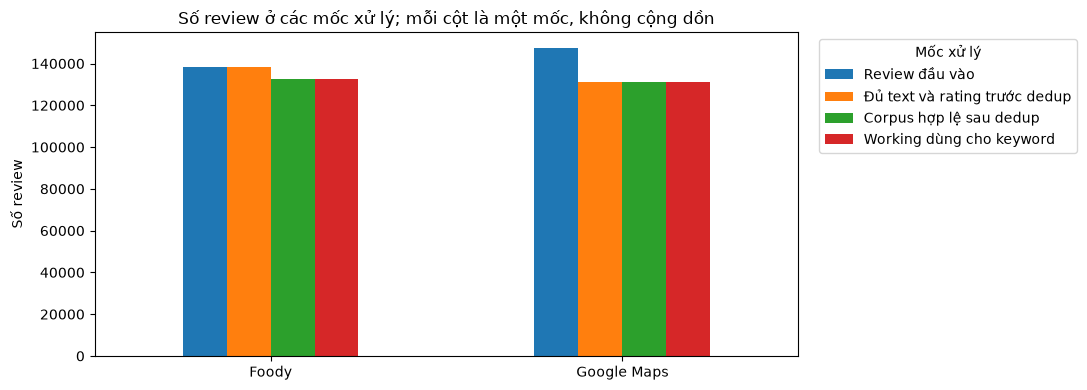

**Đọc kết quả:** từ 138,131 dòng Foody còn 132,640 review working; từ 147,565 dòng Maps còn 130,939. Foody loại 5,305 dòng theo khóa; Maps loại 0. Ở Maps, 100.0% dòng thiếu ít nhất một khóa. Số dòng bị loại khác nhau phản ánh cả schema và quy tắc kiểm tra, **không đủ để kết luận nguồn nào ít bản ghi trùng hơn**.

In [22]:
def comparison_summary(name, state):
    raw, cp_, wk_ = state['eda'], state['corpus'], state['working']
    repeated = cp_['text_norm'].duplicated(keep=False)
    return pd.Series({
        'Review đầu vào': len(raw),
        'Comment rỗng sau chuẩn hóa': int(state['text_empty'].sum()),
        'Rating thiếu': int(state['rating_missing'].sum()),
        'Đủ text và rating trước dedup': int(state['valid'].sum()),
        'Dòng thiếu ít nhất một khóa': int((~state['complete_key']).sum()),
        'Bị loại theo khóa dedup': len(state['dedup_removed']),
        'Corpus hợp lệ sau dedup': len(cp_),
        'Rating 0 trong corpus': int(cp_['rating_num'].eq(0).sum()),
        '0 token trong corpus': int(cp_['n_tokens'].eq(0).sum()),
        'Working dùng cho keyword': len(wk_),
        'Review thấp trong working': int(wk_['is_low'].sum()),
        'Baseline thấp (%) — working': 100 * wk_['is_low'].mean(),
        'Trung vị token — corpus': cp_['n_tokens'].median(),
        'P95 token — corpus': cp_['n_tokens'].quantile(.95),
        'Review thuộc text lặp (%) — corpus': 100 * repeated.mean(),
        'N-gram ổn định': int(comparison_stability[name]['stable'].sum()),
    }, name=name)

platform_summary = pd.concat([
    comparison_summary('Foody', foody_state),
    comparison_summary('Google Maps', globals()),
], axis=1)
display(platform_summary.round(3))

flow = platform_summary.loc[['Review đầu vào', 'Đủ text và rating trước dedup',
                             'Corpus hợp lệ sau dedup', 'Working dùng cho keyword']].T
ax = flow.plot.bar(figsize=(11, 4), rot=0)
ax.set(ylabel='Số review', title='Số review ở các mốc xử lý; mỗi cột là một mốc, không cộng dồn')
ax.legend(title='Mốc xử lý', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

f_n = len(foody_state['working'])
g_n = len(working)
f_base = foody_state['working']['is_low'].mean()
g_base = working['is_low'].mean()
display(Markdown(
    f'**Đọc kết quả:** từ {len(foody_state["eda"]):,} dòng Foody còn {f_n:,} review working; '
    f'từ {len(eda):,} dòng Maps còn {g_n:,}. Foody loại '
    f'{len(foody_state["dedup_removed"]):,} dòng theo khóa; Maps loại {len(dedup_removed):,}. '
    f'Ở Maps, {100*(~complete_key).mean():.1f}% dòng thiếu ít nhất một khóa. '
    'Số dòng bị loại khác nhau phản ánh cả schema và quy tắc kiểm tra, '
    '**không đủ để kết luận nguồn nào ít bản ghi trùng hơn**.'
))


**Vì sao khác nhau và ảnh hưởng gì?**

- Maps có review không có văn bản và thiếu rating trong **file đã thu thập**; Foody không có các trường hợp đó trong file đầu vào này. Có thể do phạm vi lấy mẫu, trường tùy chọn hoặc bước thu thập/chuẩn hóa trước notebook. Chưa kiểm tra được nguyên nhân nào chi phối, nên không quy toàn bộ chênh lệch cho người dùng nền tảng.
- Foody đủ các khóa nên phát hiện được nhóm trùng theo quy tắc 6 trường. Maps thiếu ngày đăng chính xác nên điều kiện đủ 5 khóa không thỏa. Bỏ device khỏi Maps không khắc phục thiếu ngày; 0 dòng bị loại chỉ có nghĩa quy tắc này không phát hiện được.
- Rating 0 và 0 token là hai loại riêng: rating 0 bị bỏ theo quyết định của pipeline; 0 token không tạo đặc trưng regex dù emoji vẫn có thể biểu đạt cảm xúc. Kết quả keyword do đó chỉ đại diện cho tập có văn bản/token và rating được giữ lại.


## 9.3. Phân phối rating và baseline

Biểu đồ trái gom điểm thành các khoảng chung, giữ nguyên điểm lẻ Foody; không làm tròn từng review. Với Maps, ba sao = 6 điểm thuộc khoảng (5, 6]. Biểu đồ phải dùng đúng working để cho thấy baseline được dùng trong các metric keyword. Chuẩn hóa theo % giúp so hai mẫu khác số dòng.


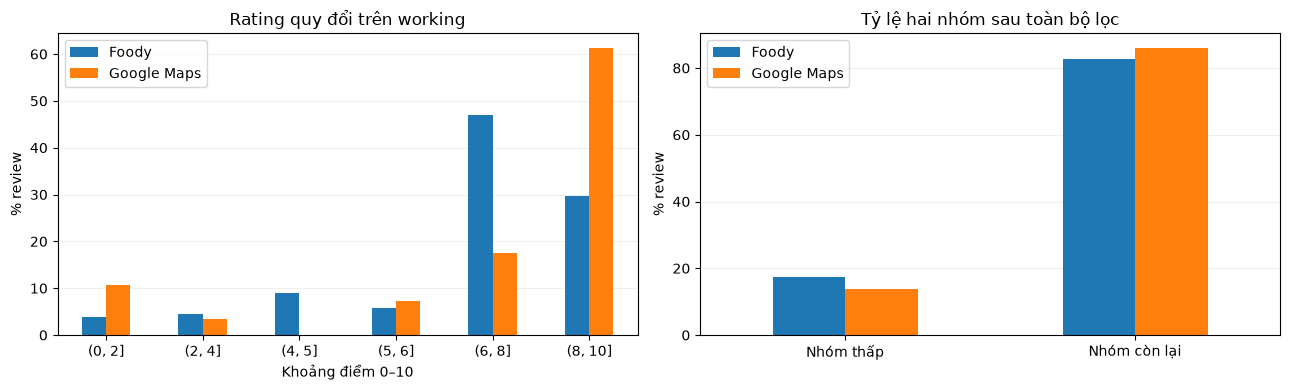

,Foody,Google Maps
Baseline thấp (%),17.449,13.916
P(thấp|cụm) tối thiểu để lift ≥2 (%),34.897,27.831
Lift tối đa lý thuyết,5.731,7.186


In [23]:
rating_bins = [0, 2, 4, 5, 6, 8, 10]
rating_labels = ['(0, 2]', '(2, 4]', '(4, 5]', '(5, 6]', '(6, 8]', '(8, 10]']
rating_comparison = pd.DataFrame({
    name: pd.cut(frame['rating_num'], rating_bins, labels=rating_labels)
            .value_counts(sort=False).reindex(rating_labels, fill_value=0) / len(frame) * 100
    for name, frame in comparison_frames.items()
})
group_comparison = pd.DataFrame({
    name: [100*frame['is_low'].mean(), 100*(~frame['is_low']).mean()]
    for name, frame in comparison_frames.items()
}, index=['Nhóm thấp', 'Nhóm còn lại'])
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
rating_comparison.plot.bar(ax=axes[0], rot=0)
axes[0].set(title='Rating quy đổi trên working', xlabel='Khoảng điểm 0–10', ylabel='% review')
group_comparison.plot.bar(ax=axes[1], rot=0)
axes[1].set(title='Tỷ lệ hai nhóm sau toàn bộ lọc', ylabel='% review', xlabel='')
for ax in axes:
    ax.grid(axis='y', alpha=.2)
    ax.set_axisbelow(True)
plt.tight_layout()
plt.show()
display(pd.DataFrame({
    name: {'Baseline thấp (%)': 100*frame['is_low'].mean(),
           'P(thấp|cụm) tối thiểu để lift ≥2 (%)': 200*frame['is_low'].mean(),
           'Lift tối đa lý thuyết': 1/frame['is_low'].mean()}
    for name, frame in comparison_frames.items()
}).round(3))


**Giải thích chênh lệch rating và lift.** Baseline là tỷ lệ review thấp trong chính mẫu đang xét, không phải một mức cố định dùng cho cả hai nền tảng. Baseline khác nhau có thể do cách chấm điểm, tập quán/người viết và cách lấy mẫu khác nhau; notebook này chưa kiểm soát được các yếu tố đó. Không suy ra chất lượng dịch vụ từ tỷ lệ thấp giữa hai nguồn.

Với một keyword $k$:

$$p_k=P(\mathrm{low}\mid k)=\frac{\mathrm{support\_low}(k)}{\mathrm{support}(k)},\qquad b=P(\mathrm{low}),\qquad \mathrm{lift}(k)=\frac{p_k}{b}.$$

Công thức này cũng bằng $P(k\mid\mathrm{low})/P(k)$ theo Bayes. Baseline Maps nhỏ hơn thì **nếu cùng $p_k$**, lift Maps lớn hơn và trần lift cao hơn. Nhưng $p_k$ thực tế cũng đổi theo nền tảng:

$$\frac{\mathrm{lift}_{G}(k)}{\mathrm{lift}_{F}(k)}=\frac{p_G(k)}{p_F(k)}\frac{b_F}{b_G}.$$

Vì vậy không có quy tắc “Maps luôn có lift cao hơn”. Nếu $p_F(k)/p_G(k)>b_F/b_G$ thì Foody có lift cao hơn. Cùng ngưỡng lift ≥2 cũng tương ứng các ngưỡng tỷ lệ thấp có điều kiện khác nhau; điều này ảnh hưởng số ứng viên được chọn.


## 9.4. Độ dài review: khác biệt ở toàn mẫu hay ở từng nhóm điểm?

Dùng working để so độ dài của chính tập phân tích keyword. Bảng thêm số review, trung vị và P95 theo nhóm thấp/còn lại; biểu đồ dùng các khoảng token chung và % trong từng nhóm. Việc này giúp tránh kết luận từ hai trung vị toàn mẫu trong khi tỷ lệ nhóm điểm khác nhau.


,Nền tảng,Nhóm,Số review,Trung vị token,P95 token,Trung bình token
0,Foody,Tất cả,132640,70.0,195.00,81.52
1,Foody,Thấp,23144,41.0,204.85,63.55
2,Foody,Còn lại,109496,78.0,194.00,85.31
3,Google Maps,Tất cả,130939,23.0,132.00,39.71
4,Google Maps,Thấp,18221,37.0,190.00,59.23
5,Google Maps,Còn lại,112718,21.0,120.00,36.55


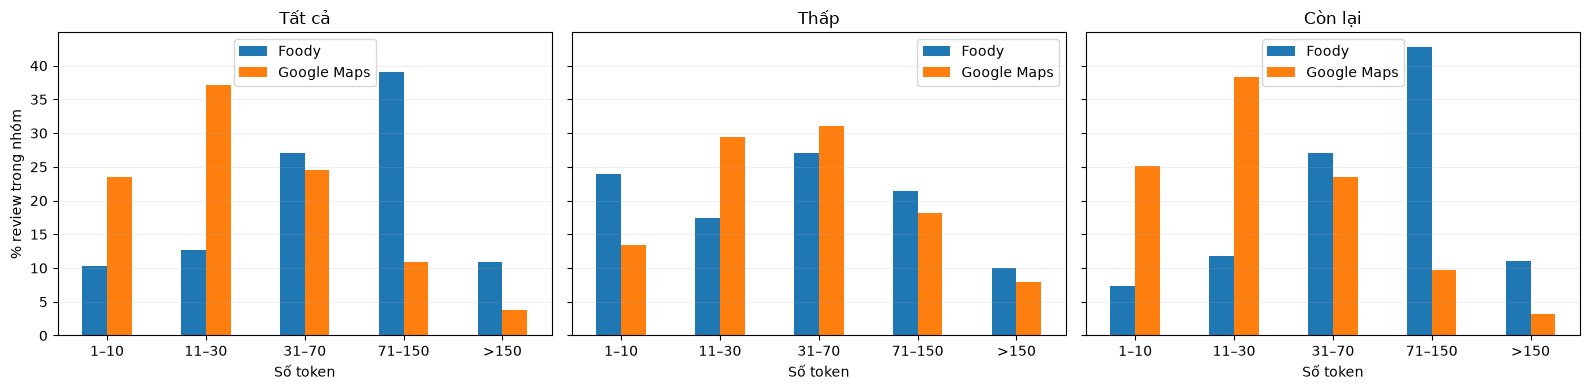

**Khác biệt quan trọng theo nhóm rating:**

- **Foody:** nhóm thấp có trung vị **41 token**, nhóm còn lại **78 token**; nhóm thấp ngắn hơn theo trung vị.
- **Google Maps:** nhóm thấp có trung vị **37 token**, nhóm còn lại **21 token**; nhóm thấp dài hơn theo trung vị.

Hướng chênh lệch độ dài giữa hai nhóm rating đảo ngược giữa hai nguồn. Đặc biệt, ở Maps nhóm thấp dài hơn có thể tạo cơ hội xuất hiện các từ kể chuyện nhiều hơn. Đây là một yếu tố gây nhiễu cần kiểm tra khi giải thích lift của “thì”, “mà”, “khách”; chưa thể coi các từ này là dấu hiệu tiêu cực tự thân hoặc kết luận độ dài là nguyên nhân duy nhất.

In [24]:
length_rows = []
length_bins = [0, 10, 30, 70, 150, np.inf]
length_labels = ['1–10', '11–30', '31–70', '71–150', '>150']
length_profiles = {}
for name, frame in comparison_frames.items():
    for label, mask in [('Tất cả', pd.Series(True, index=frame.index)),
                        ('Thấp', frame['is_low']), ('Còn lại', ~frame['is_low'])]:
        part = frame.loc[mask]
        length_rows.append({'Nền tảng': name, 'Nhóm': label, 'Số review': len(part),
                            'Trung vị token': part['n_tokens'].median(),
                            'P95 token': part['n_tokens'].quantile(.95),
                            'Trung bình token': part['n_tokens'].mean()})
        length_profiles[(name, label)] = (
            pd.cut(part['n_tokens'], length_bins, labels=length_labels)
            .value_counts(sort=False).reindex(length_labels, fill_value=0) / len(part) * 100)
length_by_group = pd.DataFrame(length_rows)
display(length_by_group.round(2))
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, group in zip(axes, ['Tất cả', 'Thấp', 'Còn lại']):
    profile = pd.DataFrame({name: length_profiles[(name, group)] for name in comparison_frames})
    profile.plot.bar(ax=ax, rot=0)
    ax.set(title=group, xlabel='Số token', ylabel='% review trong nhóm')
    ax.grid(axis='y', alpha=.2)
plt.tight_layout()
plt.show()

length_reading = []
for name in comparison_frames:
    rows = length_by_group.loc[length_by_group['Nền tảng'].eq(name)].set_index('Nhóm')
    low_med, other_med = rows.loc['Thấp', 'Trung vị token'], rows.loc['Còn lại', 'Trung vị token']
    length_reading.append(
        f'- **{name}:** nhóm thấp có trung vị **{low_med:.0f} token**, nhóm còn lại '
        f'**{other_med:.0f} token**; nhóm thấp '
        f'{"dài hơn" if low_med>other_med else "ngắn hơn"} theo trung vị.'
    )
display(Markdown('**Khác biệt quan trọng theo nhóm rating:**\n\n'+'\n'.join(length_reading)+
    '\n\nHướng chênh lệch độ dài giữa hai nhóm rating đảo ngược giữa hai nguồn. '
    'Đặc biệt, ở Maps nhóm thấp dài hơn có thể tạo cơ hội xuất hiện các từ kể chuyện nhiều hơn. '
    'Đây là một yếu tố gây nhiễu cần kiểm tra khi giải thích lift của “thì”, “mà”, “khách”; '
    'chưa thể coi các từ này là dấu hiệu tiêu cực tự thân hoặc kết luận độ dài là nguyên nhân duy nhất.'))


**Ý nghĩa đối với n-gram:** review dài có nhiều vị trí tạo 1–3 gram và nhiều cơ hội chứa một cụm. Binary=True chỉ chặn một review được đếm nhiều lần cho cùng cụm, không loại ảnh hưởng của độ dài. Nếu nhóm thấp và nhóm còn lại có độ dài khác nhau, các từ kể chuyện như “thì”, “mà”, “khách” có thể liên hệ với điểm thấp mà không mang nghĩa tiêu cực tự thân.

Các bảng này xác nhận chênh lệch độ dài; chúng chưa chứng minh độ dài gây rating thấp hoặc gây toàn bộ chênh lệch lift. Muốn kiểm tra ảnh hưởng riêng của nền tảng cần so keyword trong cùng khoảng độ dài hoặc ghép mẫu theo độ dài/rating, rồi tính lại metric. Không dùng số lượt n-gram để kết luận số keyword hữu ích, vì một lượt xuất hiện khác một cụm duy nhất.


## 9.5. Nội dung lặp: tỷ lệ giống nhau có đồng nghĩa cùng dạng lặp?

Đếm trên corpus sau dedup, cùng mốc với phần 4.4. Bên cạnh tỷ lệ review thuộc nhóm text lặp, xem số quán và tỷ lệ tập trung ở quán xuất hiện nhiều nhất. Một câu ngắn lặp ở nhiều quán có thể là cách diễn đạt thông thường; câu dài lặp nhiều lần tại một quán cần kiểm tra thêm. Các dấu hiệu này không đủ để khẳng định spam.


In [25]:
repeat_comparison_rows = []
repeat_top_tables = {}
for name, frame in comparison_corpora.items():
    text_sizes = frame.groupby('text_norm', sort=False).size()
    repeated_texts = text_sizes.loc[text_sizes.gt(1)].index
    rp = frame.loc[frame['text_norm'].isin(repeated_texts)]
    text_shop = rp.groupby(['text_norm', 'shop_id'], dropna=False).size()
    top_shop_count = text_shop.groupby(level=0).max()
    top = rp.groupby('text_norm').agg(
        so_review=('rating_num', 'size'), so_quan=('shop_id', 'nunique'),
        so_muc_rating=('rating_num', 'nunique'), n_tokens=('n_tokens', 'first'))
    top['ty_le_tai_quan_nhieu_nhat_pct'] = 100 * top_shop_count / top['so_review']
    top = top.sort_values('so_review', ascending=False).reset_index()
    repeat_top_tables[name] = top
    repeat_comparison_rows.append({'Nền tảng': name, 'Corpus': len(frame),
        'Nhóm text lặp': len(repeated_texts), 'Review thuộc text lặp': len(rp),
        '% review thuộc text lặp': 100*len(rp)/len(frame),
        'Dòng dư nếu chỉ giữ 1/text': int((text_sizes-1).clip(lower=0).sum())})
    display(Markdown(f'**{name}: 10 nội dung lặp nhiều nhất**'))
    with pd.option_context('display.max_colwidth', 100):
        display(top.head(10).round(2))
repeat_comparison = pd.DataFrame(repeat_comparison_rows)
display(repeat_comparison.round(3))

display(Markdown(
    f'**Đọc tỷ lệ lặp:** Foody có {repeat_comparison.loc[repeat_comparison["Nền tảng"].eq("Foody"), "% review thuộc text lặp"].iloc[0]:.2f}% '
    f'review thuộc nhóm text lặp, Maps có {repeat_comparison.loc[repeat_comparison["Nền tảng"].eq("Google Maps"), "% review thuộc text lặp"].iloc[0]:.2f}%. '
    'Tỷ lệ tổng khá gần nhau; cần đọc mức tập trung theo quán trong bảng phía trên để phân biệt dạng lặp. '
    'Không thể lấy riêng tỷ lệ tổng này để suy ra hai nguồn có cùng mức lặp đáng ngờ.'
))


**Foody: 10 nội dung lặp nhiều nhất**

,text_norm,so_review,so_quan,so_muc_rating,n_tokens,ty_le_tai_quan_nhieu_nhat_pct
0,ngon,482,134,22,1,12.86
1,nem nướng ngon,395,3,6,3,48.86
2,tốt,280,35,20,1,32.86
3,rất ngon,232,58,17,2,8.62
4,tuyệt vời,171,71,19,2,9.36
5,10 điểm cho chất lượng,166,8,11,5,50.00
6,vừa miệng,151,1,12,2,100.00
7,ngon tuyệt,125,34,15,2,14.40
8,dịch vụ tốt,122,24,12,3,18.85
9,"bánh ngon, mềm và thơm nứt mũi luôn ạ ☺️☺️☺️",98,1,1,9,100.00


**Google Maps: 10 nội dung lặp nhiều nhất**

,text_norm,so_review,so_quan,so_muc_rating,n_tokens,ty_le_tai_quan_nhieu_nhat_pct
0,ngon,541,310,5,1,1.66
1,được rồi,431,282,5,2,1.39
2,tốt,407,284,5,1,1.47
3,tuyệt vời,226,186,3,2,2.21
4,đồ ăn ngon,161,126,4,3,3.11
5,đẹp,93,72,4,1,9.68
6,cafe ngon,83,64,4,2,6.02
7,"đồ ăn ngon, nhân viên nhiệt tình",79,61,1,7,5.06
8,rất tốt,77,64,3,2,3.90
9,tạm được,70,66,5,2,2.86


,Nền tảng,Corpus,Nhóm text lặp,Review thuộc text lặp,% review thuộc text lặp,Dòng dư nếu chỉ giữ 1/text
0,Foody,132826,1258,7848,5.908,6590
1,Google Maps,131021,1142,7409,5.655,6267


**Đọc tỷ lệ lặp:** Foody có 5.91% review thuộc nhóm text lặp, Maps có 5.65%. Tỷ lệ tổng khá gần nhau; cần đọc mức tập trung theo quán trong bảng phía trên để phân biệt dạng lặp. Không thể lấy riêng tỷ lệ tổng này để suy ra hai nguồn có cùng mức lặp đáng ngờ.

**Tác động đến kết quả:** hai nguồn vẫn đếm theo review, nên một nội dung lặp qua nhiều review vẫn đóng góp nhiều vào support. GroupShuffleSplit theo text_norm giữ nguyên câu ở cùng một phía để tránh rò rỉ, **không giảm trọng số nội dung lặp**. Nhóm lặp lớn cũng có thể làm số dòng và baseline dao động giữa các lần chia.

Không tự xóa mọi text lặp vì có thể loại lời đánh giá hợp lệ từ nhiều người. Nếu muốn đo mức nhạy với nội dung lặp, có thể tính lại với mỗi nhóm text–quán có tổng trọng số 1, và kiểm tra cả baseline/lift/stability mới. Đó là phép kiểm tra bổ sung, chưa phải kết quả của pipeline hiện tại.


## 9.6. Đo cùng keyword trên hai nền tảng

Tập so sánh gồm **hợp của các n-gram ổn định ở ít nhất một nguồn**, cộng ba ví dụ đã dùng để minh họa: “thiếu tôn trọng”, “phục vụ tệ”, “bao giờ quay”. Ba ví dụ không được xem là đại diện cho toàn bộ từ vựng. Cùng vocabulary, regex, n-gram 1–3 và binary=True được dùng cho cả hai working.

Mỗi dòng cho biết support tổng/thấp/còn lại, P(thấp|cụm), baseline, lift, độ phủ nhóm thấp/còn lại và tình trạng kiểm chứng. Keyword không xuất hiện có lift không xác định (NaN); keyword không được chọn ở một nguồn không tự động được coi là đã chứng minh không liên hệ. **lift_all dưới đây là số mô tả toàn working, khác median_validation_lift tính trên các lần validation đủ mẫu.**


In [26]:
illustrative_terms = ['thiếu tôn trọng', 'phục vụ tệ', 'bao giờ quay']
comparison_terms = sorted(set(illustrative_terms).union(*[
    set(table.loc[table['stable'], 'keyword']) for table in comparison_stability.values()
]))
comparison_vectorizer = CountVectorizer(
    vocabulary={term: i for i, term in enumerate(comparison_terms)},
    token_pattern=TOKEN_PATTERN, ngram_range=(1, 3),
    lowercase=False, binary=True, dtype=np.int32,
)
comparison_vectorizer.fit(comparison_frames['Foody']['text_norm'].iloc[:1])
keyword_comparison_parts = []
for name, frame in comparison_frames.items():
    total = count_support(comparison_vectorizer, frame['text_norm'])
    low = count_support(comparison_vectorizer, frame.loc[frame['is_low'], 'text_norm'])
    n_low = int(frame['is_low'].sum())
    n_high = len(frame)-n_low
    p_low = np.divide(low, total, out=np.full(len(total), np.nan), where=total>0)
    table = pd.DataFrame({'keyword': comparison_terms, 'platform': name,
        'support_all': total, 'support_low': low, 'support_other': total-low,
        'p_low_pct': 100*p_low, 'baseline_pct': 100*n_low/len(frame),
        'lift_all': p_low/(n_low/len(frame)),
        'coverage_low_pct': 100*low/n_low,
        'coverage_other_pct': 100*(total-low)/n_high})
    stability_cols = ['keyword', 'stable', 'assessment', 'n_selected', 'n_evaluable',
                      'positive_rate', 'median_validation_lift']
    table = table.merge(comparison_stability[name][stability_cols], on='keyword', how='left',
                        validate='one_to_one')
    table['assessment'] = table['assessment'].fillna('Không được chọn trong 5 lần discovery')
    keyword_comparison_parts.append(table)
keyword_comparison = pd.concat(keyword_comparison_parts, ignore_index=True)
display(keyword_comparison.loc[keyword_comparison['keyword'].isin(illustrative_terms)]
        .sort_values(['keyword', 'platform']).round(3))

# Tính chung tất cả keyword trong tập so sánh, không chỉ 3 ví dụ.
keyword_wide = keyword_comparison.pivot(index='keyword', columns='platform',
    values=['support_all', 'support_low', 'p_low_pct', 'lift_all', 'coverage_low_pct'])
common_supported = keyword_wide.loc[
    keyword_wide['support_all'].ge(30).all(axis=1)
    & keyword_wide['support_low'].ge(10).all(axis=1)
    & keyword_wide['lift_all'].gt(0).all(axis=1)
].copy()
common_supported[('comparison', 'log2_lift_maps_over_foody')] = np.log2(
    common_supported[('lift_all', 'Google Maps')] / common_supported[('lift_all', 'Foody')])
contrast = common_supported[('comparison', 'log2_lift_maps_over_foody')]
maps_higher_terms = contrast.loc[contrast.gt(0)].nlargest(3).index.tolist()
foody_higher_terms = contrast.loc[contrast.lt(0)].nsmallest(3).index.tolist()
selected_terms = list(dict.fromkeys(illustrative_terms + maps_higher_terms + foody_higher_terms))
display(Markdown(
    f'Có **{len(comparison_terms):,} cụm** trong hợp ổn định và ví dụ; '
    f'**{len(common_supported):,} cụm** có support ≥30 và support thấp ≥10 ở cả hai nguồn. '
    f'Trong tập đủ mẫu này: Maps có lift cao hơn ở **{int(contrast.gt(0).sum()):,} cụm**, '
    f'Foody cao hơn ở **{int(contrast.lt(0).sum()):,} cụm**. '
    'Đây là mô tả tập keyword đã chọn, không phải tỷ lệ cho mọi n-gram có thể có. '
    'Các ngưỡng 30/10 chỉ dùng cho bảng so sánh đủ mẫu, không thay tiêu chí ổn định phần 8.'
))
keyword_contrast_examples = keyword_comparison.loc[
    keyword_comparison['keyword'].isin(selected_terms)].sort_values(['keyword', 'platform'])
display(keyword_contrast_examples.round(3))


,keyword,platform,support_all,support_low,support_other,p_low_pct,baseline_pct,lift_all,coverage_low_pct,coverage_other_pct,stable,assessment,n_selected,n_evaluable,positive_rate,median_validation_lift
193,bao giờ quay,Foody,888,812,76,91.441,17.449,5.241,3.508,0.069,True,Ổn định theo ngưỡng,5.0,5.0,1.0,5.222
5635,bao giờ quay,Google Maps,658,630,28,95.745,13.916,6.880,3.458,0.025,True,Ổn định theo ngưỡng,5.0,5.0,1.0,6.989
3324,phục vụ tệ,Foody,233,176,57,75.536,17.449,4.329,0.760,0.052,True,Ổn định theo ngưỡng,5.0,5.0,1.0,4.586
8766,phục vụ tệ,Google Maps,265,246,19,92.830,13.916,6.671,1.350,0.017,True,Ổn định theo ngưỡng,5.0,5.0,1.0,6.785
3728,thiếu tôn trọng,Foody,74,61,13,82.432,17.449,4.724,0.264,0.012,True,Ổn định theo ngưỡng,5.0,5.0,1.0,4.910
9170,thiếu tôn trọng,Google Maps,113,107,6,94.690,13.916,6.805,0.587,0.005,True,Ổn định theo ngưỡng,5.0,5.0,1.0,7.155


Có **5,442 cụm** trong hợp ổn định và ví dụ; **4,689 cụm** có support ≥30 và support thấp ≥10 ở cả hai nguồn. Trong tập đủ mẫu này: Maps có lift cao hơn ở **4,648 cụm**, Foody cao hơn ở **41 cụm**. Đây là mô tả tập keyword đã chọn, không phải tỷ lệ cho mọi n-gram có thể có. Các ngưỡng 30/10 chỉ dùng cho bảng so sánh đủ mẫu, không thay tiêu chí ổn định phần 8.

,keyword,platform,support_all,support_low,support_other,p_low_pct,baseline_pct,lift_all,coverage_low_pct,coverage_other_pct,stable,assessment,n_selected,n_evaluable,positive_rate,median_validation_lift
193,bao giờ quay,Foody,888,812,76,91.441,17.449,5.241,3.508,0.069,True,Ổn định theo ngưỡng,5.0,5.0,1.0,5.222
5635,bao giờ quay,Google Maps,658,630,28,95.745,13.916,6.880,3.458,0.025,True,Ổn định theo ngưỡng,5.0,5.0,1.0,6.989
290,bát canh,Foody,140,12,128,8.571,17.449,0.491,0.052,0.117,NaN,Không được chọn trong 5 lần discovery,NaN,NaN,NaN,NaN
5732,bát canh,Google Maps,57,35,22,61.404,13.916,4.413,0.192,0.020,True,Ổn định theo ngưỡng,5.0,4.0,1.0,4.401
1057,dịch vụ tốt,Foody,384,196,188,51.042,17.449,2.925,0.847,0.172,True,Ổn định theo ngưỡng,5.0,5.0,1.0,3.178
6499,dịch vụ tốt,Google Maps,765,20,745,2.614,13.916,0.188,0.110,0.661,NaN,Không được chọn trong 5 lần discovery,NaN,NaN,NaN,NaN
1678,không ngồi,Foody,120,10,110,8.333,17.449,0.478,0.043,0.100,NaN,Không được chọn trong 5 lần discovery,NaN,NaN,NaN,NaN
7120,không ngồi,Google Maps,43,21,22,48.837,13.916,3.510,0.115,0.020,True,Ổn định theo ngưỡng,5.0,3.0,1.0,4.337
3324,phục vụ tệ,Foody,233,176,57,75.536,17.449,4.329,0.760,0.052,True,Ổn định theo ngưỡng,5.0,5.0,1.0,4.586
8766,phục vụ tệ,Google Maps,265,246,19,92.830,13.916,6.671,1.350,0.017,True,Ổn định theo ngưỡng,5.0,5.0,1.0,6.785


### Biểu đồ và cơ chế tạo chênh lệch lift

Scatter hiển thị toàn bộ tập đủ mẫu của mục 9.6; điểm trên đường chéo có lift Maps cao hơn, điểm dưới đường chéo có lift Foody cao hơn. Các biểu đồ cột dùng ba ví dụ minh họa và tối đa ba cụm chênh lệch mạnh theo mỗi hướng; đây là ví dụ có chủ đích về cơ chế, không phải mẫu ngẫu nhiên.


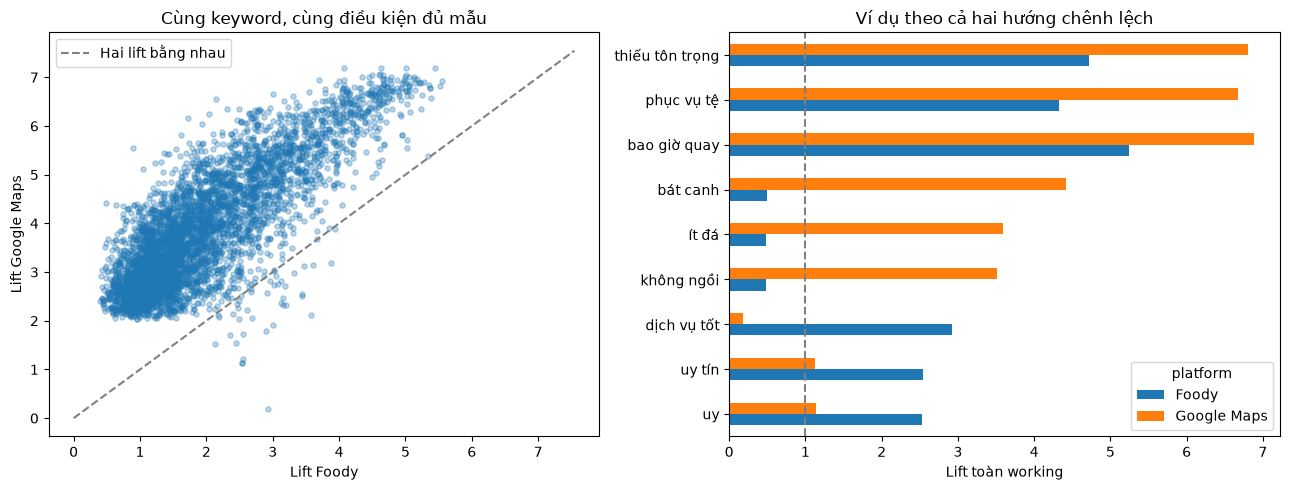

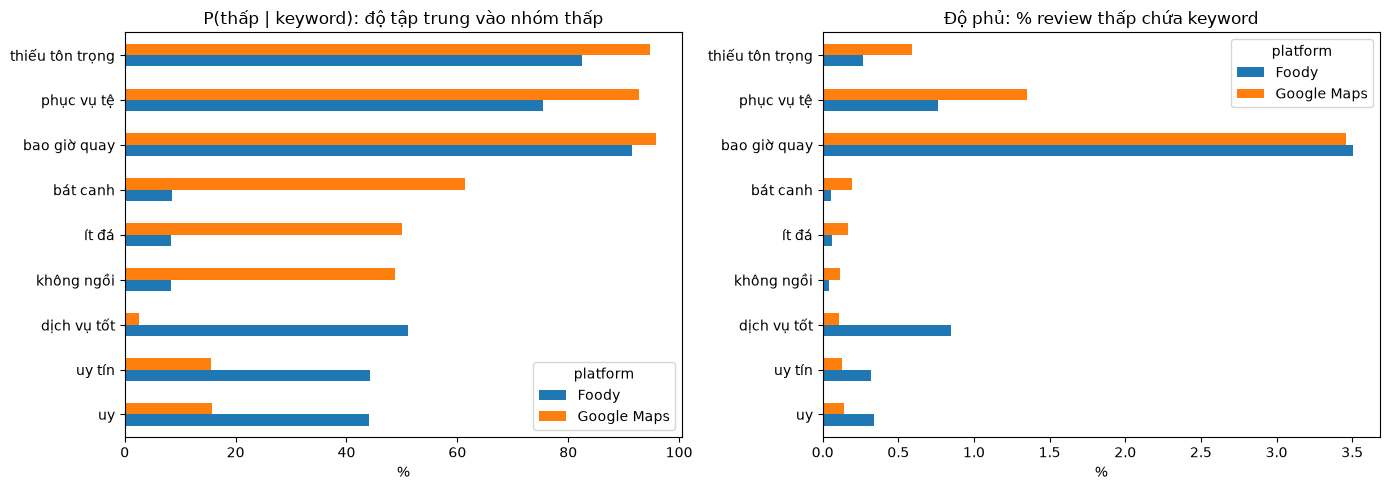

**Baseline Foody/Maps = 1.254.** Nếu P(thấp|cụm) bằng nhau, lift Maps sẽ gấp 1.254 lần Foody. Dữ liệu thực tế:

- **“bát canh”**: P(thấp|cụm) Foody 8.57%, Maps 61.40%; lift Foody 0.491, Maps 4.413. Tỷ số P(thấp|cụm) Foody/Maps = 0.140, nhỏ hơn tỷ số baseline 1.254; do đó lift Maps cao hơn.
- **“dịch vụ tốt”**: P(thấp|cụm) Foody 51.04%, Maps 2.61%; lift Foody 2.925, Maps 0.188. Tỷ số P(thấp|cụm) Foody/Maps = 19.523, lớn hơn tỷ số baseline 1.254; do đó lift Foody cao hơn.

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(common_supported[('lift_all', 'Foody')],
                common_supported[('lift_all', 'Google Maps')], alpha=.3, s=14)
if not common_supported.empty:
    bound = float(common_supported['lift_all'].max().max())*1.05
    axes[0].plot([0, bound], [0, bound], '--', color='gray', label='Hai lift bằng nhau')
axes[0].set(xlabel='Lift Foody', ylabel='Lift Google Maps', title='Cùng keyword, cùng điều kiện đủ mẫu')
axes[0].legend()
lift_examples = keyword_contrast_examples.pivot(index='keyword', columns='platform', values='lift_all')
lift_examples.reindex(selected_terms).iloc[::-1].plot.barh(ax=axes[1])
axes[1].axvline(1, color='gray', linestyle='--')
axes[1].set(xlabel='Lift toàn working', ylabel='', title='Ví dụ theo cả hai hướng chênh lệch')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, metric, title in zip(axes, ['p_low_pct', 'coverage_low_pct'],
    ['P(thấp | keyword): độ tập trung vào nhóm thấp', 'Độ phủ: % review thấp chứa keyword']):
    values = keyword_contrast_examples.pivot(index='keyword', columns='platform', values=metric)
    values.reindex(selected_terms).iloc[::-1].plot.barh(ax=ax)
    ax.set(title=title, xlabel='%', ylabel='')
plt.tight_layout()
plt.show()

baseline_ratio = f_base/g_base
explanation_lines = [
    f'**Baseline Foody/Maps = {baseline_ratio:.3f}.** Nếu P(thấp|cụm) bằng nhau, '
    f'lift Maps sẽ gấp {baseline_ratio:.3f} lần Foody. Dữ liệu thực tế:',
]
for term in maps_higher_terms[:1] + foody_higher_terms[:1]:
    row = keyword_wide.loc[term]
    p_f, p_g = row[('p_low_pct', 'Foody')], row[('p_low_pct', 'Google Maps')]
    l_f, l_g = row[('lift_all', 'Foody')], row[('lift_all', 'Google Maps')]
    explanation_lines.append(
        f'- **“{term}”**: P(thấp|cụm) Foody {p_f:.2f}%, Maps {p_g:.2f}%; '
        f'lift Foody {l_f:.3f}, Maps {l_g:.3f}. '
        f'Tỷ số P(thấp|cụm) Foody/Maps = {p_f/p_g:.3f}, '
        f'{"lớn hơn" if p_f/p_g > baseline_ratio else "nhỏ hơn"} tỷ số baseline {baseline_ratio:.3f}; '
        f'do đó lift {"Foody" if l_f > l_g else "Maps"} cao hơn.'
    )
display(Markdown(explanation_lines[0]+'\n\n'+'\n'.join(explanation_lines[1:])))


**Rút ra được gì từ keyword?**

- Lift đo mức liên hệ tương đối với baseline riêng; độ phủ cho biết cụm chạm tới bao nhiêu review thấp. Lift cao nhưng support/độ phủ thấp có thể là dấu hiệu mạnh nhưng hiếm; độ phủ cao nhưng lift thấp thường ít đặc trưng hơn cho nhóm thấp.
- Bảng cùng keyword cho phép xác định cụm nào xuất hiện chủ yếu trong review thấp ở một nguồn nhưng phổ biến hơn trong nhóm còn lại của nguồn kia. Chênh lệch đó là cơ chế thống kê trực tiếp tạo chênh lệch lift. Vì sao cách dùng cụm khác nhau cần đọc ngữ cảnh; độ dài, nội dung lặp, tập quán và cách chấm điểm là các khả năng cần kiểm tra.
- Không đồng nhất một cụm với sắc thái cố định: “bao giờ quay” có thể đi sau “không” hoặc “chưa biết”; n-gram 1–3 token có thể cắt mất phủ định/ngữ cảnh. Một cụm đạt ổn định cũng chưa tự trở thành từ khóa tiêu cực có ý nghĩa.


### 9.6.1. Đọc mẫu của cụm có lift Foody cao hơn

Tự lấy cụm chênh lệch mạnh nhất theo hướng Foody trong tập đủ mẫu ở mục 9.6, rồi xem phân phối rating và mẫu ngữ cảnh của cả hai nguồn. Mẫu hiển thị ưu tiên văn bản ngắn, khác nội dung để dễ kiểm tra, **không phải mẫu ngẫu nhiên đại diện**. Giữ nguyên toàn bộ review khi tính thống kê.


In [28]:
if foody_higher_terms:
    audit_term = foody_higher_terms[0]
    audit_vectorizer = CountVectorizer(
        vocabulary={audit_term: 0}, token_pattern=TOKEN_PATTERN,
        ngram_range=(1, 3), binary=True, lowercase=False,
    )
    audit_vectorizer.fit(comparison_frames['Foody']['text_norm'].iloc[:1])
    display(Markdown(f'**Cụm cần đọc ngữ cảnh: “{audit_term}”**'))
    audit_summary = []
    audit_rating_tables = []
    for name, frame in comparison_frames.items():
        mask = np.zeros(len(frame), dtype=bool)
        for start in range(0, len(frame), BATCH_SIZE):
            matrix = audit_vectorizer.transform(frame['text_norm'].iloc[start:start+BATCH_SIZE])
            mask[start:start+matrix.shape[0]] = np.asarray(matrix.sum(axis=1)).ravel()>0
        rows = frame.loc[mask]
        audit_summary.append({'Nền tảng': name, 'Review chứa cụm': len(rows),
            '% thấp': 100*rows['is_low'].mean(),
            'Text khác nhau': rows['text_norm'].nunique(),
            '% thuộc text lặp trong nhóm chứa cụm': 100*rows['text_norm'].duplicated(keep=False).mean(),
            'Review có toàn văn đúng bằng cụm': int(rows['text_norm'].eq(audit_term).sum())})
        rating_table = rows.groupby('rating_num').size().rename('Số review').reset_index()
        rating_table['Nền tảng'] = name
        audit_rating_tables.append(rating_table)
        for label, group_mask in [('Thấp', rows['is_low']), ('Còn lại', ~rows['is_low'])]:
            examples = (rows.loc[group_mask].sort_values('n_tokens')
                        .drop_duplicates('text_norm').head(3))
            display(Markdown(f'**{name} — {label}:** tối đa 3 nội dung ngắn để kiểm tra.'))
            with pd.option_context('display.max_colwidth', 240):
                display(examples[['shop_id', 'rating_num', 'n_tokens', 'comment_text']])
    display(pd.DataFrame(audit_summary).round(3))
    display(pd.concat(audit_rating_tables, ignore_index=True)
            .pivot(index='rating_num', columns='Nền tảng', values='Số review').fillna(0).astype(int))
    display(Markdown(
        '**Cách diễn giải:** đối chiếu nội dung với điểm số trước khi gọi cụm này là tiêu cực. '
        'Nếu câu có nghĩa tích cực vẫn thường mang rating thuộc nhóm thấp ở Foody, '
        'lift cao phản ánh liên hệ với **nhãn rating đang dùng**, không chứng minh cụm mang nghĩa tiêu cực. '
        'Nội dung lặp cũng có thể góp phần làm tăng support; cần xem cả số text khác nhau và phân phối rating. '
        'Muốn xác định vì sao điểm và lời nhận xét lệch nhau phải kiểm tra dữ liệu nguồn/chuẩn hóa hoặc gán nhãn thủ công; '
        'chưa đủ bằng chứng quy nguyên nhân cho hành vi người dùng.'
    ))
else:
    print('Không có cụm đủ mẫu có lift Foody cao hơn để đọc mẫu theo quy tắc này.')


**Cụm cần đọc ngữ cảnh: “dịch vụ tốt”**

**Foody — Thấp:** tối đa 3 nội dung ngắn để kiểm tra.

,shop_id,rating_num,n_tokens,comment_text
4303,res-beefsteak-kieu-dam-59-nam-ky-khoi-nghia,5.0,3,Dịch vụ tốt
18078,vuon-sinh-thai-xeo-nhum,5.0,4,Dịch vụ tốt nha
11345,lumos-coffee-cake-tran-hung-dao,5.0,4,Dịch vụ tốt ạ


**Foody — Còn lại:** tối đa 3 nội dung ngắn để kiểm tra.

,shop_id,rating_num,n_tokens,comment_text
7627,res-beefsteak-kieu-dam-59-nam-ky-khoi-nghia,10.0,3,dịch vụ tốt
18053,vuon-sinh-thai-xeo-nhum,9.8,4,"Tốt, dịch vụ tốt!"
99620,com-tam-tuyen-bach-dang,8.6,5,"Ngon thơm , dịch vụ tốt"


**Google Maps — Thấp:** tối đa 3 nội dung ngắn để kiểm tra.

... (2 outputs left out)

,shop_id,rating_num,n_tokens,comment_text
7885,gmap:e60d679cdf555f84905ee88d,10.0,3,dịch vụ tốt
102313,gmap:895441af2866924431f5ec81,8.0,3,Dịch vụ tốt!
11981,gmap:b746fbed72ebade5fa737d11,10.0,3,Dịch vụ tốt !


,Nền tảng,Review chứa cụm,% thấp,Text khác nhau,% thuộc text lặp trong nhóm chứa cụm,Review có toàn văn đúng bằng cụm
0,Foody,384,51.042,208,50.781,122
1,Google Maps,765,2.614,725,6.275,27


Nền tảng,Foody,Google Maps
rating_num,,
1.0,1,0
1.4,1,0
2.0,0,15
2.6,1,0
2.8,1,0
4.0,0,5
4.6,1,0
4.8,2,0
5.0,189,0


**Cách diễn giải:** đối chiếu nội dung với điểm số trước khi gọi cụm này là tiêu cực. Nếu câu có nghĩa tích cực vẫn thường mang rating thuộc nhóm thấp ở Foody, lift cao phản ánh liên hệ với **nhãn rating đang dùng**, không chứng minh cụm mang nghĩa tiêu cực. Nội dung lặp cũng có thể góp phần làm tăng support; cần xem cả số text khác nhau và phân phối rating. Muốn xác định vì sao điểm và lời nhận xét lệch nhau phải kiểm tra dữ liệu nguồn/chuẩn hóa hoặc gán nhãn thủ công; chưa đủ bằng chứng quy nguyên nhân cho hành vi người dùng.

## 9.7. Độ ổn định và phần giao giữa hai nguồn

So số cụm ổn định **cùng tiêu chí**, phần giao/hợp và tỷ lệ được kiểm chứng. Số cụm ổn định nhiều hơn không chứng minh dữ liệu tốt hơn: nó còn phụ thuộc baseline, số review thấp, phân bố từ vựng, độ dài và mức lặp. Các lần chia được lặp trên cùng dữ liệu, không phải 5 bộ test độc lập.


In [29]:
stable_sets = {name: set(table.loc[table['stable'], 'keyword'])
               for name, table in comparison_stability.items()}
shared_stable = stable_sets['Foody'] & stable_sets['Google Maps']
union_stable = stable_sets['Foody'] | stable_sets['Google Maps']
stability_summary = pd.DataFrame({
    name: {'Được chọn ít nhất một lần': len(table),
           'Đủ ≥3 lần kiểm chứng': int(table['n_evaluable'].ge(MIN_EVALUABLE_SPLITS).sum()),
           'Ổn định': int(table['stable'].sum()),
           'Ổn định / từng được chọn (%)': 100*table['stable'].mean()}
    for name, table in comparison_stability.items()
})
display(stability_summary.round(3))
display(pd.DataFrame({'Phạm vi': ['Chỉ Foody', 'Cùng ổn định', 'Chỉ Google Maps', 'Hợp'],
    'Số cụm': [len(stable_sets['Foody']-shared_stable), len(shared_stable),
              len(stable_sets['Google Maps']-shared_stable), len(union_stable)]}))
display(Markdown(
    f'**Jaccard = giao/hợp = {len(shared_stable)/len(union_stable):.3f}** '
    if union_stable else 'Không có cụm ổn định để tính Jaccard.'
))
split_comparison = pd.concat([
    pd.DataFrame(foody_state['split_reports']).assign(platform='Foody'),
    pd.DataFrame(split_reports).assign(platform='Google Maps'),
], ignore_index=True)
validation_comparison = split_comparison.loc[split_comparison['Tập'].eq('Validation')]
display(validation_comparison.groupby('platform').agg(
    review_min=('Số review', 'min'), review_max=('Số review', 'max'),
    baseline_min_pct=('Tỷ lệ điểm thấp (%)', 'min'),
    baseline_max_pct=('Tỷ lệ điểm thấp (%)', 'max')).round(3))

# Cụm giao được xếp theo độ phủ thấp nhỏ hơn giữa hai nguồn:
# ưu tiên cụm có độ phủ ở cả hai, thay vì chọn riêng top của một nguồn.
shared_preview = keyword_wide.loc[sorted(shared_stable)].copy()
shared_preview[('comparison', 'min_coverage_low_pct')] = shared_preview['coverage_low_pct'].min(axis=1)
display(shared_preview.sort_values(('comparison', 'min_coverage_low_pct'),
                                   ascending=False).head(15).round(3))


,Foody,Google Maps
Được chọn ít nhất một lần,28512.000,39540.000
Đủ ≥3 lần kiểm chứng,2781.000,5907.000
Ổn định,1834.000,4592.000
Ổn định / từng được chọn (%),6.432,11.614


,Phạm vi,Số cụm
0,Chỉ Foody,850
1,Cùng ổn định,984
2,Chỉ Google Maps,3608
3,Hợp,5442


**Jaccard = giao/hợp = 0.181** 

,review_min,review_max,baseline_min_pct,baseline_max_pct
platform,,,,
Foody,26384,26932,16.96,17.6
Google Maps,25778,26609,13.38,14.0


support_all             support_low             p_low_pct  \
platform         Foody Google Maps       Foody Google Maps     Foody   
keyword                                                                
tệ              3877.0      5279.0      2662.0      4602.0    68.661   
thái độ         4734.0      5200.0      2487.0      3773.0    52.535   
hỏi             5790.0      3871.0      2128.0      2210.0    36.753   
vọng            5065.0      2594.0      2055.0      1252.0    40.573   
bao giờ         3532.0      1508.0      1817.0      1209.0    51.444   
xin             3916.0      2362.0      1486.0      1507.0    37.947   
thất            4226.0      2086.0      1903.0      1089.0    45.031   
thất vọng       3845.0      1659.0      1813.0      1042.0    47.152   
dở              2720.0      1952.0      1287.0      1341.0    47.316   
trả             2323.0      1563.0      1233.0      1048.0    53.078   
lời             2230.0      1653.0      1037.0      1053.0    46.502   
khách hàng      2352.0      2790.0       983.0      1307.0    41.794   
không bao       1494.0       849.0      1087.0       743.0    72.758   
hiểu            2832.0      1470.0      1052.0       728.0    37.147   
tính tiền       3190.0      1203.0      1192.0       715.0    37.367   

                       lift_all             coverage_low_pct              \
platform   Google Maps    Foody Google Maps            Foody Google Maps   
keyword                                                                    
tệ              87.176    3.935       6.265           11.502      25.257   
thái độ         72.558    3.011       5.214           10.746      20.707   
hỏi             57.091    2.106       4.103            9.195      12.129   
vọng            48.265    2.325       3.468            8.879       6.871   
bao giờ         80.172    2.948       5.761            7.851       6.635   
xin             63.802    2.175       4.585            6.421       8.271   
thất            52.205    2.581       3.752            8.222       5.977   
thất vọng       62.809    2.702       4.514            7.834       5.719   
dở              68.699    2.712       4.937            5.561       7.360   
trả             67.051    3.042       4.818            5.328       5.752   
lời             63.702    2.665       4.578            4.481       5.779   
khách hàng      46.846    2.395       3.366            4.247       7.173   
không bao       87.515    4.170       6.289            4.697       4.078   
hiểu            49.524    2.129       3.559            4.545       3.995   
tính tiền       59.435    2.142       4.271            5.150       3.924   

                     comparison  
platform   min_coverage_low_pct  
keyword                          
tệ                       11.502  
thái độ                  10.746  
hỏi                       9.195  
vọng                      6.871  
bao giờ                   6.635  
xin                       6.421  
thất                      5.977  
thất vọng                 5.719  
dở                        5.561  
trả                       5.328  
lời                       4.481  
khách hàng                4.247  
không bao                 4.078  
hiểu                      3.995  
tính tiền                 3.924

**Giải thích số lượng ổn định khác nhau:** baseline nhỏ hơn làm ngưỡng lift ≥2 tương ứng mức P(thấp|cụm) thấp hơn và trần lift cao hơn. Số lần đủ mẫu validation còn phụ thuộc cụm phổ biến đến đâu, không chỉ tổng số review. Bảng trên mô tả các cơ chế có thể góp phần; chưa tách được phần đóng góp riêng của mỗi cơ chế.

Cụm chỉ ổn định ở một nguồn có thể do thiếu support, ít lần được chọn, ít lần đủ mẫu hoặc lift không giữ được ở nguồn kia. Phải đọc các cột assessment/n_selected/n_evaluable trong bảng 9.6 trước khi giải thích; không gọi tất cả là “khác biệt ngôn ngữ”. Phần giao là danh sách ưu tiên đọc ngữ cảnh trên cả hai nguồn, chưa phải bộ keyword đã kiểm định khả năng chuyển sang nền tảng mới.


## 9.8. Kết luận so sánh và hướng đi tiếp

| Quan sát có thể khẳng định từ lần chạy | Cách giải thích được dữ liệu hỗ trợ | Thao tác tiếp theo chịu ảnh hưởng |
|---|---|---|
| Số dòng mất ở mỗi bước khác nhau | Schema và điều kiện đầy đủ khóa khác nhau; Maps thiếu ngày chính xác | Báo rõ khả năng phát hiện trùng; kiểm tra mẫu lặp thay vì khẳng định Maps sạch hơn |
| Baseline điểm thấp khác nhau | Hai mẫu có tỷ lệ nhóm rating khác nhau; đổi thang không làm đồng nhất hành vi chấm điểm | Dùng baseline riêng, báo cả P(thấp|cụm), lift và support |
| Độ dài khác nhau ở toàn mẫu và các nhóm rating theo bảng 9.4 | Mỗi review có cơ hội chứa n-gram khác nhau | So trong cùng khoảng độ dài hoặc ghép mẫu trước khi quy chênh lệch cho nền tảng |
| Text lặp còn lại có mức tập trung quán khác nhau | Cùng text không đồng nghĩa cùng bản ghi; chia nhóm chỉ ngăn rò rỉ | Audit nội dung tập trung; kiểm tra độ nhạy với trọng số text–quán nếu cần |
| Cùng keyword có thể cho lift cao hơn theo cả hai hướng | Lift phụ thuộc đồng thời P(thấp|cụm) và baseline; xem phép phân rã 9.6 | Giữ đối chiếu cùng cụm, tránh so hai danh sách top khác nhau rồi suy rộng |
| Tập ổn định có phần giao và phần riêng | Tiêu chí ổn định là kết quả của support, mức liên hệ và phép chia trên từng mẫu | Đọc ngữ cảnh cả hai nguồn; kiểm chứng riêng khả năng dùng chung keyword |

**Giới hạn của diễn giải “tại sao”:** tác động số học của baseline, thiếu khóa và quy tắc đếm là các cơ chế đã xác định. Khác biệt tập người dùng, loại quán, thời gian và cách thu thập là giả thuyết hợp lý nhưng chưa được kiểm soát trong notebook này. Do đó, kết luận hướng tới đặc điểm của **hai bộ dữ liệu** và cách xây dựng/kiểm chứng keyword, không quy kết nền tảng nào tiêu cực hơn hoặc có dịch vụ tốt hơn.


In [30]:
# Kiểm tra tính nhất quán của phần bổ sung, không đặt cứng số liệu đầu ra.
assert comparison_frames['Google Maps'] is working
assert foody_state['working'] is not working
assert len(keyword_comparison) == 2*len(comparison_terms)
assert not keyword_comparison.duplicated(['keyword', 'platform']).any()
for name, frame in comparison_frames.items():
    part = keyword_comparison.loc[keyword_comparison['platform'].eq(name)]
    assert part['support_low'].le(part['support_all']).all()
    assert part['support_all'].le(len(frame)).all()
    assert part['support_other'].eq(part['support_all']-part['support_low']).all()
    assert part.loc[part['support_all'].eq(0), 'lift_all'].isna().all()
    present = part['support_all'].gt(0)
    assert np.allclose(part.loc[present, 'lift_all'],
        part.loc[present, 'p_low_pct']/part.loc[present, 'baseline_pct'])
    assert part['coverage_low_pct'].between(0, 100).all()
    assert np.isclose(rating_comparison[name].sum(), 100)
assert len(shared_stable) <= min(map(len, stable_sets.values()))
assert FOODY_NOTEBOOK.read_bytes() == foody_reference_bytes
print('PASS: số dòng, support, baseline, lift, độ phủ và phần giao nhất quán; notebook Foody giữ nguyên.')


PASS: số dòng, support, baseline, lift, độ phủ và phần giao nhất quán; notebook Foody giữ nguyên.
